In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

print("Tudo funcionando")

Tudo funcionando



###### 1. CARREGAMENTO DOS DADOS

In [2]:
# Ajuste os caminhos conforme sua estrutura de pastas
orders = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_orders_dataset.csv")
order_items = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_order_items_dataset.csv")
payments = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_order_payments_dataset.csv")
order_reviews = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_order_reviews_dataset.csv")

###### 2. CONVERSÃO DE DATAS

In [474]:
date_cols = {
    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
    "order_items": ["shipping_limit_date"],
    "order_reviews": ["review_creation_date", "review_answer_timestamp"],
}
 
for col in date_cols["orders"]:
    if col in orders.columns:
        orders[col] = pd.to_datetime(orders[col])
 
for col in date_cols["order_items"]:
    if col in order_items.columns:
        order_items[col] = pd.to_datetime(order_items[col])
 
for col in date_cols["order_reviews"]:
    if col in order_reviews.columns:
        order_reviews[col] = pd.to_datetime(order_reviews[col])

###### 3. AGREGAÇÕES (evita duplicatas no merge)

In [475]:
# --- order_items: 1 linha por pedido ---
items_agg = order_items.groupby("order_id").agg(
    qtd_itens           = ("order_item_id", "count"),
    qtd_sellers         = ("seller_id",     "nunique"),
    qtd_produtos_unicos = ("product_id",    "nunique"),
    receita_produtos    = ("price",         "sum"),
    receita_frete       = ("freight_value", "sum"),
    shipping_limit_date = ("shipping_limit_date", "max"),  # data limite mais tardia
).assign(
    receita_total = lambda df: df["receita_produtos"] + df["receita_frete"],
    ticket_medio  = lambda df: df["receita_produtos"] / df["qtd_itens"],
)

In [476]:
# --- payments: 1 linha por pedido ---
payments_agg = payments.groupby("order_id").agg(
    valor_pago          = ("payment_value",       "sum"),
    max_parcelas        = ("payment_installments", "max"),
    qtd_transacoes      = ("payment_sequential",  "count"),
    formas_pagamento    = ("payment_type", lambda x: " | ".join(sorted(x.unique()))),
).reset_index()

In [477]:
# Flag: pagamento parcelado
payments_agg["pagamento_parcelado"] = payments_agg["max_parcelas"] > 1

In [478]:
# --- reviews: 1 linha por pedido (pega o mais recente se houver mais de 1) ---
reviews_agg = (
    order_reviews
    .sort_values("review_creation_date", ascending=False)
    .groupby("order_id")
    .agg(
        review_score          = ("review_score",          "first"),
        review_comment_title  = ("review_comment_title",  "first"),
        review_comment_message= ("review_comment_message","first"),
        review_creation_date  = ("review_creation_date",  "first"),
        review_answer_date    = ("review_answer_timestamp","first"),
        qtd_reviews           = ("review_score",          "count"),
    )
)

###### 4. MONTAGEM DA TABELA FATO

In [479]:
fact_orders = (
    orders
    .merge(items_agg,    on="order_id", how="left")
    .merge(payments_agg, on="order_id", how="left")
    .merge(reviews_agg,  on="order_id", how="left")
)

###### 5. FEATURES DERIVADAS ÚTEIS PARA EDA

In [480]:
# Tempo de entrega (dias)
fact_orders["dias_ate_entrega"] = (
    fact_orders["order_delivered_customer_date"]
    - fact_orders["order_purchase_timestamp"]
).dt.days

In [481]:
# Atraso em relação à estimativa (positivo = atrasado, negativo = adiantado)
fact_orders["dias_atraso"] = (
    fact_orders["order_delivered_customer_date"]
    - fact_orders["order_estimated_delivery_date"]
).dt.days

In [482]:
# Entregou no prazo?
fact_orders["entregue_no_prazo"] = fact_orders["dias_atraso"] <= 0

In [483]:
# Tempo de aprovação (horas)
fact_orders["horas_ate_aprovacao"] = (
    fact_orders["order_approved_at"]
    - fact_orders["order_purchase_timestamp"]
).dt.total_seconds() / 3600

In [484]:
# Período do dia da compra
def periodo_do_dia(hora):
    if pd.isna(hora):
        return np.nan
    if 6 <= hora < 12:
        return "manhã"
    elif 12 <= hora < 18:
        return "tarde"
    elif 18 <= hora < 24:
        return "noite"
    else:
        return "madrugada"
 
fact_orders["hora_compra"]    = fact_orders["order_purchase_timestamp"].dt.hour
fact_orders["periodo_compra"] = fact_orders["hora_compra"].apply(periodo_do_dia)
fact_orders["mes_compra"]     = fact_orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
fact_orders["ano_compra"]     = fact_orders["order_purchase_timestamp"].dt.year
fact_orders["dia_semana"]     = fact_orders["order_purchase_timestamp"].dt.day_name()

In [485]:
# Diferença entre valor pago e receita (pode indicar desconto ou erro)
fact_orders["diferenca_valor"] = fact_orders["valor_pago"] - fact_orders["receita_total"]

In [486]:
# Classificação do review
def classifica_review(score):
    if pd.isna(score):
        return "sem avaliação"
    elif score >= 4:
        return "positivo"
    elif score == 3:
        return "neutro"
    else:
        return "negativo"
 
fact_orders["sentimento_review"] = fact_orders["review_score"].apply(classifica_review)

###### 6. DIAGNÓSTICO RÁPIDO DA TABELA FATO

In [487]:
print("=" * 60)
print("DIAGNÓSTICO DA TABELA FATO")
print("=" * 60)
print(f"\nLinhas (pedidos):  {len(fact_orders):,}")
print(f"Colunas:           {fact_orders.shape[1]}")
print(f"\nPedidos únicos em orders:       {orders['order_id'].nunique():,}")
print(f"Pedidos únicos na tabela fato:  {fact_orders['order_id'].nunique():,}")
 
print("\n--- Nulos por coluna relevante ---")
colunas_checar = [
    "receita_total", "valor_pago", "review_score",
    "dias_ate_entrega", "dias_atraso", "horas_ate_aprovacao"
]
print(fact_orders[colunas_checar].isnull().sum().to_string())
 
print("\n--- Distribuição de status ---")
print(fact_orders["order_status"].value_counts().to_string())

DIAGNÓSTICO DA TABELA FATO

Linhas (pedidos):  99,441
Colunas:           38

Pedidos únicos em orders:       99,441
Pedidos únicos na tabela fato:  99,441

--- Nulos por coluna relevante ---
receita_total           775
valor_pago                1
review_score            768
dias_ate_entrega       2965
dias_atraso            2965
horas_ate_aprovacao     160

--- Distribuição de status ---
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2


###### 7. RESUMO ESTATÍSTICO PRINCIPAL

In [488]:
print("\n" + "=" * 60)
print("RESUMO ESTATÍSTICO")
print("=" * 60)
 
metricas = [
    "receita_total", "receita_produtos", "receita_frete",
    "valor_pago", "ticket_medio", "qtd_itens",
    "review_score", "dias_ate_entrega", "dias_atraso",
]
metricas_existentes = [m for m in metricas if m in fact_orders.columns]
print(fact_orders[metricas_existentes].describe().round(2).to_string())
 


RESUMO ESTATÍSTICO
       receita_total  receita_produtos  receita_frete  valor_pago  ticket_medio  qtd_itens  review_score  dias_ate_entrega  dias_atraso
count       98666.00          98666.00       98666.00    99440.00      98666.00   98666.00      98673.00          96476.00     96476.00
mean          160.58            137.75          22.82      160.99        125.92       1.14          4.09             12.09       -11.88
std           220.47            210.65          21.65      221.95        190.99       0.54          1.35              9.55        10.18
min             9.59              0.85           0.00        0.00          0.85       1.00          1.00              0.00      -147.00
25%            61.98             45.90          13.85       62.01         41.99       1.00          4.00              6.00       -17.00
50%           105.29             86.90          17.17      105.29         79.00       1.00          5.00             10.00       -12.00
75%           176.87        

###### 8. ANÁLISES PRONTAS PARA USO

In [489]:
# --- 8a. Receita mensal ---
receita_mensal = (
    fact_orders[fact_orders["order_status"] == "delivered"]
    .groupby("mes_compra")
    .agg(
        pedidos       = ("order_id",      "count"),
        receita_total = ("receita_total", "sum"),
        ticket_medio  = ("ticket_medio",  "mean"),
    )
    .sort_index()
)

In [490]:
# --- 8b. Taxa de atraso por mês ---
taxa_atraso = (
    fact_orders
    .dropna(subset=["entregue_no_prazo"])
    .groupby("mes_compra")
    .agg(
        pedidos_entregues = ("order_id",         "count"),
        atrasados         = ("entregue_no_prazo", lambda x: (~x).sum()),
    )
    .assign(taxa_atraso_pct = lambda df: (df["atrasados"] / df["pedidos_entregues"] * 100).round(1))
    .sort_index()
)

In [491]:
# --- 8c. Review por forma de pagamento ---
review_pagamento = (
    fact_orders
    .dropna(subset=["review_score", "formas_pagamento"])
    .groupby("formas_pagamento")
    .agg(
        pedidos      = ("order_id",     "count"),
        media_review = ("review_score", "mean"),
        media_valor  = ("valor_pago",   "mean"),
    )
    .round(2)
    .sort_values("pedidos", ascending=False)
)

In [492]:
# --- 8d. Distribuição de sentimento ---
sentimento = fact_orders["sentimento_review"].value_counts()
 
print("\n--- Receita mensal (top 5 meses) ---")
print(receita_mensal.tail(5).to_string())
 
print("\n--- Taxa de atraso (últimos 3 meses) ---")
print(taxa_atraso.tail(3).to_string())
 
print("\n--- Review por forma de pagamento ---")
print(review_pagamento.to_string())
 
print("\n--- Sentimento dos reviews ---")
print(sentimento.to_string())


--- Receita mensal (top 5 meses) ---
            pedidos  receita_total  ticket_medio
mes_compra                                      
2018-04        6798     1132878.93    131.149315
2018-05        6749     1128774.52    130.303774
2018-06        6099     1011978.29    128.177783
2018-07        6159     1027807.28    129.058676
2018-08        6351      985491.64    122.043896

--- Taxa de atraso (últimos 3 meses) ---
            pedidos_entregues  atrasados  taxa_atraso_pct
mes_compra                                               
2018-08                  6512        554              8.5
2018-09                    16         16            100.0
2018-10                     4          4            100.0

--- Review por forma de pagamento ---
                       pedidos  media_review  media_valor
formas_pagamento                                         
credit_card              73683          4.09       166.81
boleto                   19636          4.09       144.51
credit_card | vo

###### 9. EXPORTAR

In [493]:
fact_orders.to_csv("fact_orders.csv", index=False)
print("\n✓ Tabela fato salva em fact_orders.csv")
print(f"  {len(fact_orders):,} linhas × {fact_orders.shape[1]} colunas")


✓ Tabela fato salva em fact_orders.csv
  99,441 linhas × 38 colunas


In [494]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

###### GRAFICOS CONFIGURAÇÃO VISUAL 

In [495]:
CORES = {
    "primaria":   "#7F77DD",   # purple
    "secundaria": "#1D9E75",   # teal
    "alerta":     "#D85A30",   # coral
    "neutro":     "#888780",   # gray
    "positivo":   "#639922",   # green
    "amarelo":    "#BA7517",   # amber
}
PALETTE_SENTIMENTO = {
    "positivo":      CORES["positivo"],
    "neutro":        CORES["amarelo"],
    "negativo":      CORES["alerta"],
    "sem avaliação": CORES["neutro"],
}
 
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({
    "figure.facecolor":  "white",
    "axes.facecolor":    "#F8F8F8",
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.titlesize":    13,
    "axes.titleweight":  "bold",
    "axes.labelsize":    11,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
})

###### CARREGAR TABELA FATO

In [496]:
df = pd.read_csv("fact_orders.csv", parse_dates=[
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
])
 
# Garantir colunas derivadas caso não venham no CSV
if "mes_compra" not in df.columns:
    df["mes_compra"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
if "sentimento_review" not in df.columns:
    def classifica(s):
        if pd.isna(s): return "sem avaliação"
        return "positivo" if s >= 4 else ("neutro" if s == 3 else "negativo")
    df["sentimento_review"] = df["review_score"].apply(classifica)
 
delivered = df[df["order_status"] == "delivered"].copy()
 

###### Pedido e Receita 

✓ fig1_temporal.png


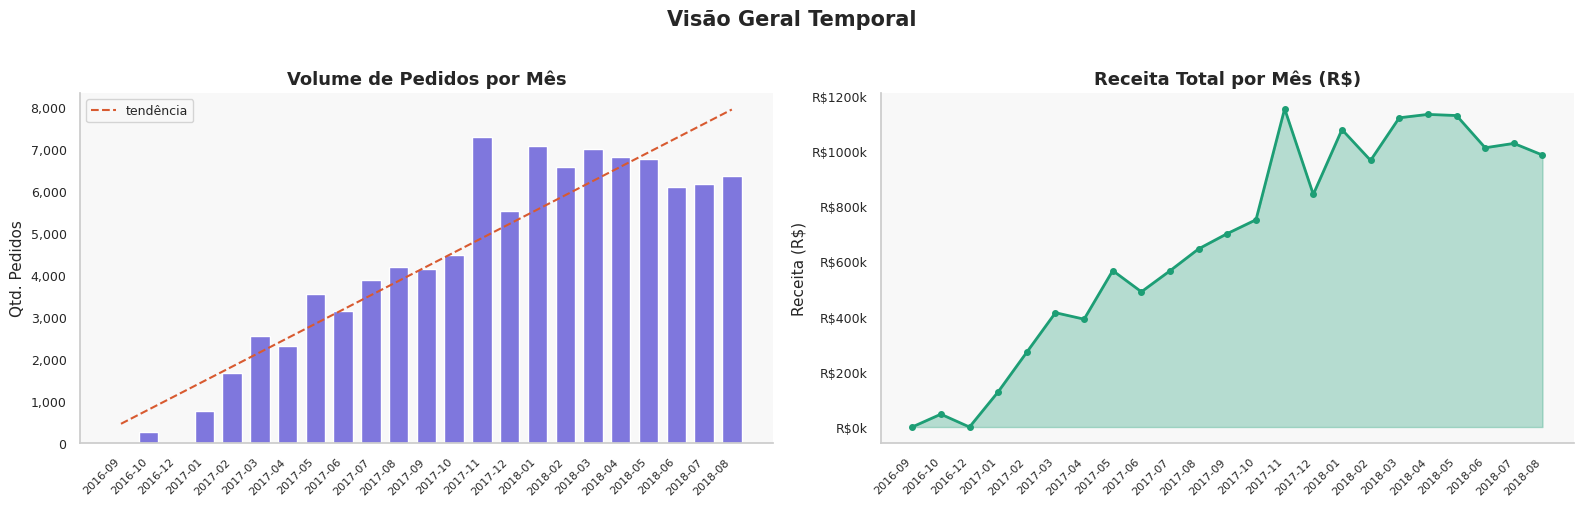

In [497]:
fig1, axes = plt.subplots(1, 2, figsize=(16, 5))
fig1.suptitle("Visão Geral Temporal", fontsize=15, fontweight="bold", y=1.01)
 
# 1a. Pedidos por mês
pedidos_mes = delivered.groupby("mes_compra")["order_id"].count()
ax = axes[0]
bars = ax.bar(range(len(pedidos_mes)), pedidos_mes.values, color=CORES["primaria"], width=0.7)
ax.set_xticks(range(len(pedidos_mes)))
ax.set_xticklabels(pedidos_mes.index, rotation=45, ha="right", fontsize=8)
ax.set_title("Volume de Pedidos por Mês")
ax.set_ylabel("Qtd. Pedidos")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
# Linha de tendência
z = np.polyfit(range(len(pedidos_mes)), pedidos_mes.values, 1)
p = np.poly1d(z)
ax.plot(range(len(pedidos_mes)), p(range(len(pedidos_mes))),
        color=CORES["alerta"], linestyle="--", linewidth=1.5, label="tendência")
ax.legend(fontsize=9)
 
# 1b. Receita mensal
receita_mes = delivered.groupby("mes_compra")["receita_total"].sum()
ax2 = axes[1]
ax2.fill_between(range(len(receita_mes)), receita_mes.values,
                 alpha=0.3, color=CORES["secundaria"])
ax2.plot(range(len(receita_mes)), receita_mes.values,
         color=CORES["secundaria"], linewidth=2, marker="o", markersize=4)
ax2.set_xticks(range(len(receita_mes)))
ax2.set_xticklabels(receita_mes.index, rotation=45, ha="right", fontsize=8)
ax2.set_title("Receita Total por Mês (R$)")
ax2.set_ylabel("Receita (R$)")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R${x/1000:.0f}k"))
 
plt.tight_layout()
fig1.savefig("fig1_temporal.png", dpi=150, bbox_inches="tight")
print("✓ fig1_temporal.png")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)


In [498]:
print(rfm.columns)

Index(['customer_id', 'ultima_compra', 'frequencia', 'primeiro_pedido',
       'recencia_dias', 'valor_total', 'ticket_medio', 'lifetime_dias',
       'r_score', 'f_score', 'm_score', 'rfm_score', 'risco_recencia',
       'risco_frequencia', 'risco_valor', 'review_medio', 'risco_review',
       'churn_score', 'segmento', 'nivel_risco'],
      dtype='str')


###### Histograma Ticket Médio

✓ fig2_valores.png


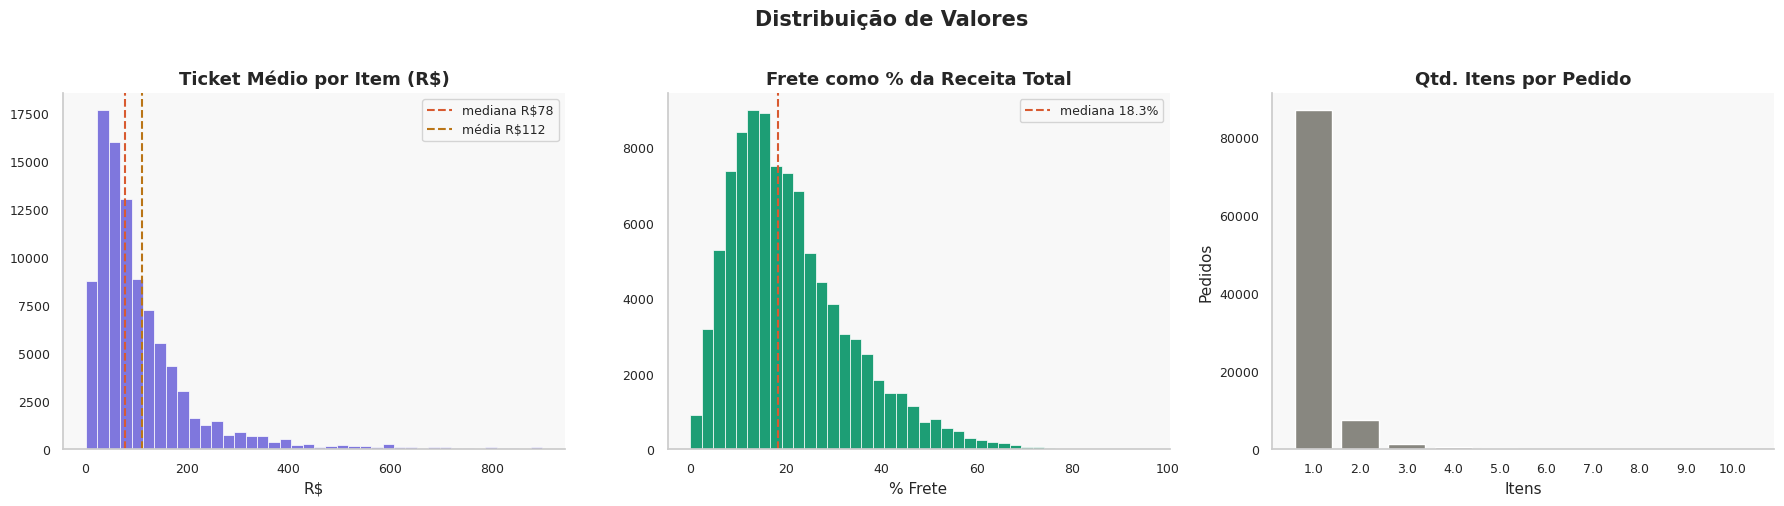

In [499]:
fig2, axes = plt.subplots(1, 3, figsize=(18, 5))
fig2.suptitle("Distribuição de Valores", fontsize=15, fontweight="bold", y=1.01)
 
# 2a. Ticket médio (sem outliers extremos)
ax = axes[0]
data_ticket = delivered["ticket_medio"].dropna()
data_ticket = data_ticket[data_ticket < data_ticket.quantile(0.99)]
ax.hist(data_ticket, bins=40, color=CORES["primaria"], edgecolor="white", linewidth=0.5)
ax.axvline(data_ticket.median(), color=CORES["alerta"], linestyle="--",
           linewidth=1.5, label=f"mediana R${data_ticket.median():.0f}")
ax.axvline(data_ticket.mean(), color=CORES["amarelo"], linestyle="--",
           linewidth=1.5, label=f"média R${data_ticket.mean():.0f}")
ax.set_title("Ticket Médio por Item (R$)")
ax.set_xlabel("R$")
ax.legend(fontsize=9)
 
# 2b. Frete como % da receita
ax2 = axes[1]
delivered_copy = delivered.copy()
delivered_copy["pct_frete"] = (delivered_copy["receita_frete"] /
                                delivered_copy["receita_total"] * 100).clip(0, 100)
data_frete = delivered_copy["pct_frete"].dropna()
ax2.hist(data_frete, bins=40, color=CORES["secundaria"], edgecolor="white", linewidth=0.5)
ax2.axvline(data_frete.median(), color=CORES["alerta"], linestyle="--",
            linewidth=1.5, label=f"mediana {data_frete.median():.1f}%")
ax2.set_title("Frete como % da Receita Total")
ax2.set_xlabel("% Frete")
ax2.legend(fontsize=9)
 
# 2c. Número de itens por pedido
ax3 = axes[2]
itens_count = delivered["qtd_itens"].dropna().value_counts().sort_index().head(10)
ax3.bar(itens_count.index.astype(str), itens_count.values,
        color=CORES["neutro"], edgecolor="white")
ax3.set_title("Qtd. Itens por Pedido")
ax3.set_xlabel("Itens")
ax3.set_ylabel("Pedidos")
 
plt.tight_layout()
fig2.savefig("fig2_valores.png", dpi=150, bbox_inches="tight")
print("✓ fig2_valores.png")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

###### Tempo de entrega 

✓ fig3_entregas.png


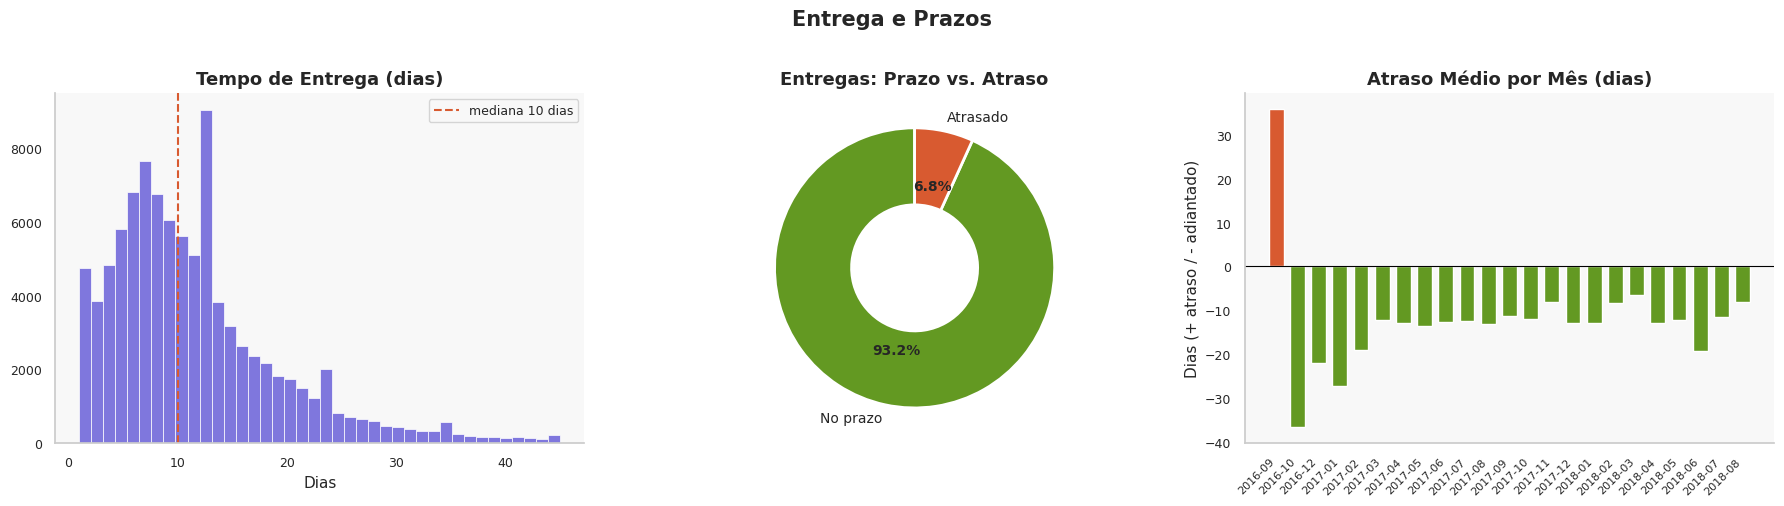

In [500]:
fig3, axes = plt.subplots(1, 3, figsize=(18, 5))
fig3.suptitle("Entrega e Prazos", fontsize=15, fontweight="bold", y=1.01)
 
# 3a. Distribuição de dias até entrega
ax = axes[0]
data_entrega = delivered["dias_ate_entrega"].dropna()
data_entrega = data_entrega[(data_entrega > 0) & (data_entrega < data_entrega.quantile(0.99))]
ax.hist(data_entrega, bins=40, color=CORES["primaria"], edgecolor="white", linewidth=0.5)
ax.axvline(data_entrega.median(), color=CORES["alerta"], linestyle="--",
           linewidth=1.5, label=f"mediana {data_entrega.median():.0f} dias")
ax.set_title("Tempo de Entrega (dias)")
ax.set_xlabel("Dias")
ax.legend(fontsize=9)
 
# 3b. Atraso vs. Pontual (donut)
ax2 = axes[1]
entregues_com_data = delivered.dropna(subset=["entregue_no_prazo"])
counts = entregues_com_data["entregue_no_prazo"].value_counts()
labels_map = {True: "No prazo", False: "Atrasado"}
labels = [labels_map[k] for k in counts.index]
cores_donut = [CORES["positivo"] if k else CORES["alerta"] for k in counts.index]
cores_donut = [CORES["positivo"] if k else CORES["alerta"] for k in counts.index]
wedges, texts, autotexts = ax2.pie(
    counts.values, labels=labels, autopct="%1.1f%%",
    colors=cores_donut, startangle=90,
    wedgeprops={"width": 0.55, "edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 10},
)
for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight("bold")
ax2.set_title("Entregas: Prazo vs. Atraso")
 
# 3c. Atraso médio por mês
ax3 = axes[2]
atraso_mes = (
    delivered
    .dropna(subset=["dias_atraso"])
    .groupby("mes_compra")["dias_atraso"]
    .mean()
)
cores_atraso = [CORES["alerta"] if v > 0 else CORES["positivo"] for v in atraso_mes.values]
ax3.bar(range(len(atraso_mes)), atraso_mes.values, color=cores_atraso, width=0.7)
ax3.axhline(0, color="black", linewidth=0.8, linestyle="-")
ax3.set_xticks(range(len(atraso_mes)))
ax3.set_xticklabels(atraso_mes.index, rotation=45, ha="right", fontsize=8)
ax3.set_title("Atraso Médio por Mês (dias)")
ax3.set_ylabel("Dias (+ atraso / - adiantado)")
 
plt.tight_layout()
fig3.savefig("fig3_entregas.png", dpi=150, bbox_inches="tight")
print("✓ fig3_entregas.png")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

###### Review e Satisfação

✓ fig4_reviews.png


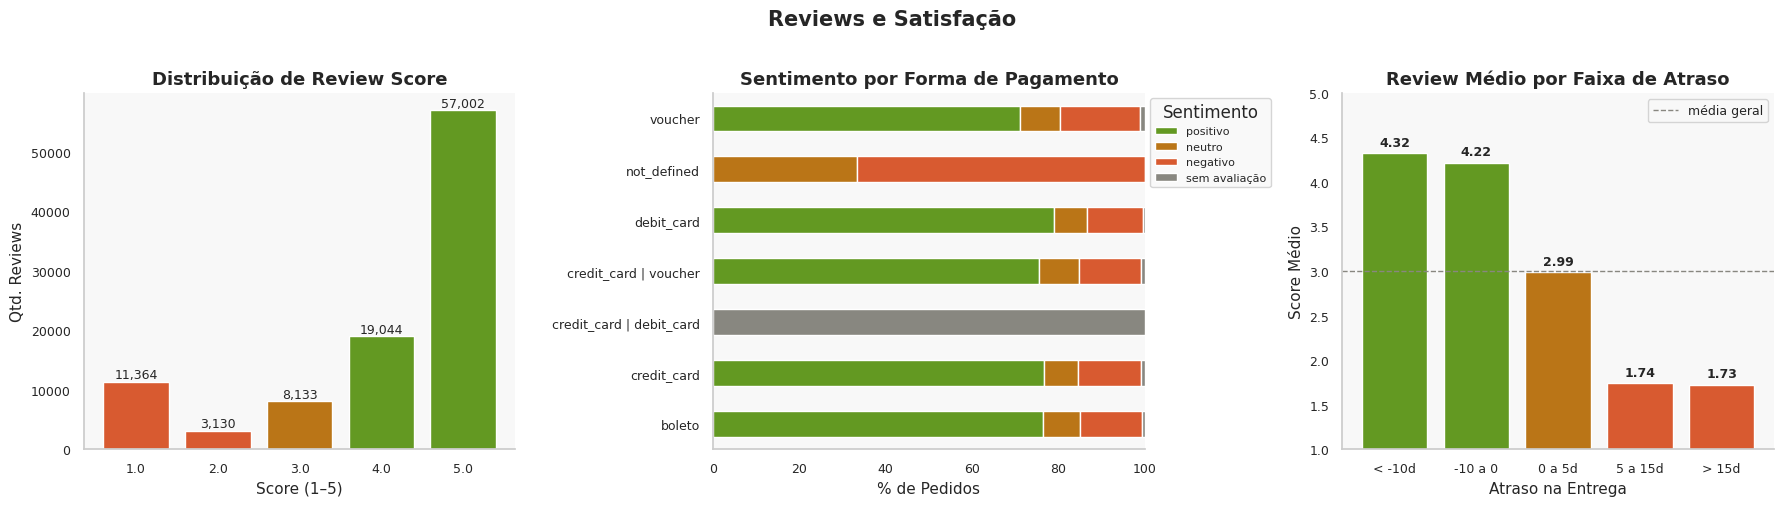

In [501]:
fig4, axes = plt.subplots(1, 3, figsize=(18, 5))
fig4.suptitle("Reviews e Satisfação", fontsize=15, fontweight="bold", y=1.01)
 
# 4a. Distribuição de scores
ax = axes[0]
scores = df["review_score"].dropna().value_counts().sort_index()
cores_score = [CORES["alerta"], CORES["alerta"], CORES["amarelo"],
               CORES["positivo"], CORES["positivo"]]
bars = ax.bar(scores.index.astype(str), scores.values,
              color=cores_score, edgecolor="white")
for bar, val in zip(bars, scores.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f"{val:,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Distribuição de Review Score")
ax.set_xlabel("Score (1–5)")
ax.set_ylabel("Qtd. Reviews")
 
# 4b. Sentimento por forma de pagamento
ax2 = axes[1]
sentimento_pag = (
    df.dropna(subset=["formas_pagamento", "sentimento_review"])
    .groupby(["formas_pagamento", "sentimento_review"])
    .size()
    .unstack(fill_value=0)
)
sentimento_pag_pct = sentimento_pag.div(sentimento_pag.sum(axis=1), axis=0) * 100
ordem_sentimento = [c for c in ["positivo", "neutro", "negativo", "sem avaliação"]
                    if c in sentimento_pag_pct.columns]
sentimento_pag_pct[ordem_sentimento].plot(
    kind="barh", stacked=True, ax=ax2,
    color=[PALETTE_SENTIMENTO.get(c, CORES["neutro"]) for c in ordem_sentimento],
    edgecolor="white",
)
ax2.set_title("Sentimento por Forma de Pagamento")
ax2.set_xlabel("% de Pedidos")
ax2.legend(title="Sentimento", bbox_to_anchor=(1, 1), fontsize=8)
ax2.set_ylabel("")
 
# 4c. Review score médio vs. dias de atraso (dispersão agrupada)
ax3 = axes[2]
atraso_bins = pd.cut(delivered["dias_atraso"].dropna(),
                     bins=[-999, -10, 0, 5, 15, 999],
                     labels=["< -10d", "-10 a 0", "0 a 5d", "5 a 15d", "> 15d"])
atraso_review = (
    delivered
    .assign(faixa_atraso=atraso_bins)
    .dropna(subset=["faixa_atraso", "review_score"])
    .groupby("faixa_atraso", observed=True)["review_score"]
    .mean()
)
cores_faixa = [CORES["positivo"], CORES["positivo"], CORES["amarelo"],
               CORES["alerta"], CORES["alerta"]]
bars = ax3.bar(atraso_review.index.astype(str), atraso_review.values,
               color=cores_faixa, edgecolor="white")
ax3.set_ylim(1, 5)
ax3.set_title("Review Médio por Faixa de Atraso")
ax3.set_xlabel("Atraso na Entrega")
ax3.set_ylabel("Score Médio")
ax3.axhline(atraso_review.mean(), color=CORES["neutro"], linestyle="--",
            linewidth=1, label="média geral")
for bar, val in zip(bars, atraso_review.values):
    ax3.text(bar.get_x() + bar.get_width()/2, val + 0.05,
             f"{val:.2f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax3.legend(fontsize=9)
 
plt.tight_layout()
fig4.savefig("fig4_reviews.png", dpi=150, bbox_inches="tight")
print("✓ fig4_reviews.png")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

###### Pagamentos

✓ fig5_pagamentos.png


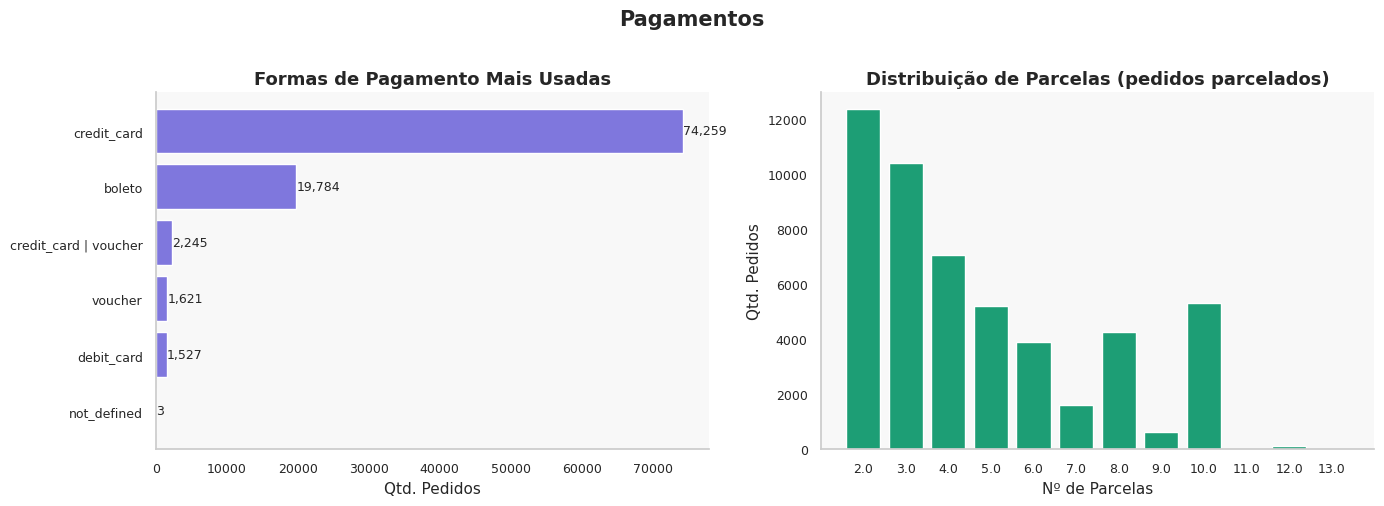

In [502]:
fig5, axes = plt.subplots(1, 2, figsize=(14, 5))
fig5.suptitle("Pagamentos", fontsize=15, fontweight="bold", y=1.01)
 
# 5a. Mix de formas de pagamento
ax = axes[0]
pag_counts = df["formas_pagamento"].value_counts().head(6)
ax.barh(pag_counts.index[::-1], pag_counts.values[::-1],
        color=CORES["primaria"], edgecolor="white")
ax.set_title("Formas de Pagamento Mais Usadas")
ax.set_xlabel("Qtd. Pedidos")
for i, val in enumerate(pag_counts.values[::-1]):
    ax.text(val + 10, i, f"{val:,}", va="center", fontsize=9)
 
# 5b. Distribuição de parcelas (pedidos parcelados)
ax2 = axes[1]
parcelados = df[df["max_parcelas"] > 1]["max_parcelas"].dropna()
parcelas_count = parcelados.value_counts().sort_index().head(12)
ax2.bar(parcelas_count.index.astype(str), parcelas_count.values,
        color=CORES["secundaria"], edgecolor="white")
ax2.set_title("Distribuição de Parcelas (pedidos parcelados)")
ax2.set_xlabel("Nº de Parcelas")
ax2.set_ylabel("Qtd. Pedidos")
 
plt.tight_layout()
fig5.savefig("fig5_pagamentos.png", dpi=150, bbox_inches="tight")
print("✓ fig5_pagamentos.png")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

###### Padroes de Compra

✓ fig6_padroes.png

✅ Todas as figuras salvas! Arquivos gerados:
   fig1_temporal.png   — Volume e receita mensal
   fig2_valores.png    — Ticket médio, frete, itens
   fig3_entregas.png   — Tempo de entrega e atraso
   fig4_reviews.png    — Scores e satisfação
   fig5_pagamentos.png — Formas e parcelas
   fig6_padroes.png    — Hora e dia da semana


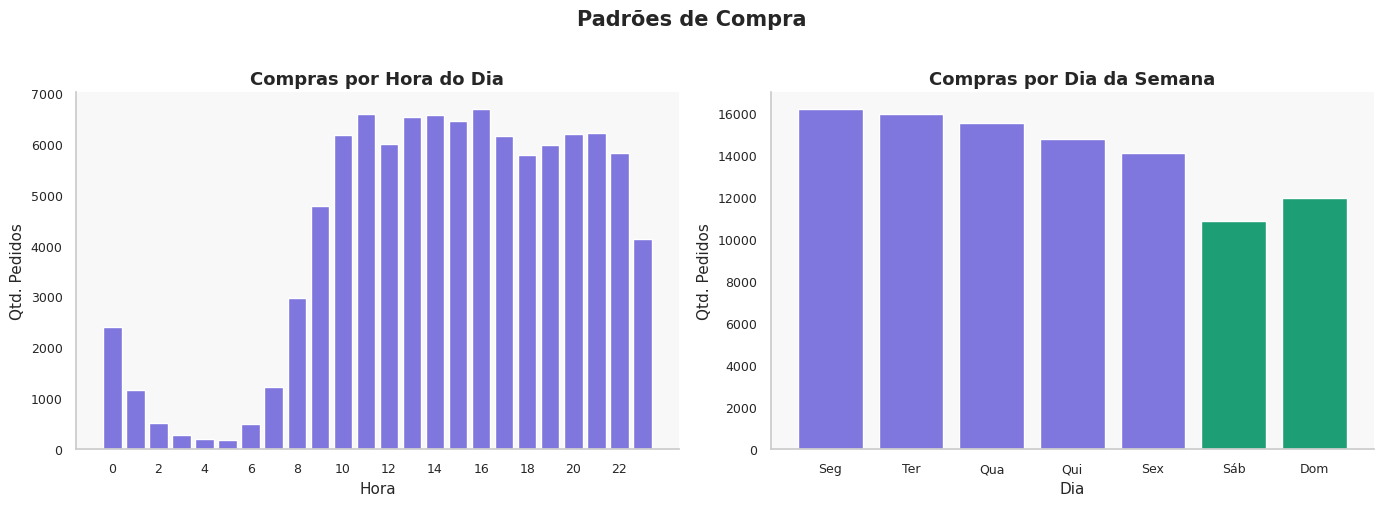

In [503]:
fig6, axes = plt.subplots(1, 2, figsize=(14, 5))
fig6.suptitle("Padrões de Compra", fontsize=15, fontweight="bold", y=1.01)
 
# 6a. Compras por hora do dia
ax = axes[0]
hora_counts = df["hora_compra"].dropna().value_counts().sort_index()
ax.bar(hora_counts.index, hora_counts.values, color=CORES["primaria"],
       edgecolor="white", width=0.8)
ax.set_title("Compras por Hora do Dia")
ax.set_xlabel("Hora")
ax.set_ylabel("Qtd. Pedidos")
ax.set_xticks(range(0, 24, 2))
 
# 6b. Compras por dia da semana
ax2 = axes[1]
ordem_dias = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
nomes_pt   = ["Seg","Ter","Qua","Qui","Sex","Sáb","Dom"]
dia_counts = df["dia_semana"].dropna().value_counts().reindex(ordem_dias, fill_value=0)
cores_dias = [CORES["secundaria"] if d in ["Saturday","Sunday"] else CORES["primaria"]
              for d in ordem_dias]
ax2.bar(nomes_pt, dia_counts.values, color=cores_dias, edgecolor="white")
ax2.set_title("Compras por Dia da Semana")
ax2.set_xlabel("Dia")
ax2.set_ylabel("Qtd. Pedidos")
 
plt.tight_layout()
fig6.savefig("fig6_padroes.png", dpi=150, bbox_inches="tight")
print("✓ fig6_padroes.png")
 
print("\n✅ Todas as figuras salvas! Arquivos gerados:")
print("   fig1_temporal.png   — Volume e receita mensal")
print("   fig2_valores.png    — Ticket médio, frete, itens")
print("   fig3_entregas.png   — Tempo de entrega e atraso")
print("   fig4_reviews.png    — Scores e satisfação")
print("   fig5_pagamentos.png — Formas e parcelas")
print("   fig6_padroes.png    — Hora e dia da semana")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

In [504]:
CORES = {
    "primaria":   "#7F77DD",
    "secundaria": "#1D9E75",
    "alerta":     "#D85A30",
    "neutro":     "#888780",
    "positivo":   "#639922",
    "amarelo":    "#BA7517",
}
 
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({
    "figure.facecolor":  "white",
    "axes.facecolor":    "#F8F8F8",
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.titlesize":    13,
    "axes.titleweight":  "bold",
    "axes.labelsize":    11,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
})
 
# =============================================================
# CARREGAR TABELA FATO
# =============================================================
df = pd.read_csv("fact_orders.csv", parse_dates=[
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
])
 
# Filtrar apenas pedidos entregues com review
base = df[
    (df["order_status"] == "delivered") &
    (df["review_score"].notna()) &
    (df["dias_ate_entrega"].notna()) &
    (df["receita_total"].notna())
].copy()
 
print(f"Base de análise: {len(base):,} pedidos entregues com review")

Base de análise: 95,824 pedidos entregues com review


In [505]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings("ignore")  

In [506]:

# --- Faixas de tempo de entrega ---
base["faixa_entrega"] = pd.cut(
    base["dias_ate_entrega"],
    bins=[0, 7, 14, 21, 30, 999],
    labels=["≤ 7d", "8–14d", "15–21d", "22–30d", "> 30d"],
)
 
# --- Faixas de preço (receita total do pedido) ---
base["faixa_preco"] = pd.qcut(
    base["receita_total"],
    q=5,
    labels=["Q1\n(mais barato)", "Q2", "Q3", "Q4", "Q5\n(mais caro)"],
    duplicates="drop",
)
 
# --- Faixas de % de frete ---
base["pct_frete"] = (base["receita_frete"] / base["receita_total"] * 100).clip(0, 100)
base["faixa_frete"] = pd.cut(
    base["pct_frete"],
    bins=[0, 10, 20, 35, 50, 100],
    labels=["≤ 10%", "10–20%", "20–35%", "35–50%", "> 50%"],
)
 
# --- Dias de atraso em faixas ---
base["faixa_atraso"] = pd.cut(
    base["dias_atraso"],
    bins=[-999, -7, 0, 3, 7, 999],
    labels=["Muito\nadiantado", "No prazo", "Até 3d\natrasado", "3–7d\natrasado", "> 7d\natrasado"],
)
 
# =============================================================
# ESTATÍSTICAS DESCRITIVAS
# =============================================================
print("\n=== CORRELAÇÕES COM REVIEW SCORE ===")
corr_entrega = base["dias_ate_entrega"].corr(base["review_score"])
corr_atraso  = base["dias_atraso"].corr(base["review_score"])
corr_preco   = base["receita_total"].corr(base["review_score"])
corr_frete   = base["pct_frete"].corr(base["review_score"])
corr_ticket  = base["ticket_medio"].corr(base["review_score"])
 
print(f"  Dias até entrega:  r = {corr_entrega:.3f}")
print(f"  Dias de atraso:    r = {corr_atraso:.3f}")
print(f"  Receita total:     r = {corr_preco:.3f}")
print(f"  % Frete:           r = {corr_frete:.3f}")
print(f"  Ticket médio:      r = {corr_ticket:.3f}")
 
# Teste de significância (Spearman — mais robusto para scores ordinais)
print("\n=== CORRELAÇÃO DE SPEARMAN (robusta para scores) ===")
for var, label in [
    ("dias_ate_entrega", "Dias até entrega"),
    ("dias_atraso",      "Dias de atraso"),
    ("receita_total",    "Receita total"),
    ("pct_frete",        "% Frete"),
]:
    sub = base[[var, "review_score"]].dropna()
    r, p = stats.spearmanr(sub[var], sub["review_score"])
    sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
    print(f"  {label:<22} r = {r:+.3f}  p = {p:.2e}  {sig}")


=== CORRELAÇÕES COM REVIEW SCORE ===
  Dias até entrega:  r = -0.334
  Dias de atraso:    r = -0.267
  Receita total:     r = -0.042
  % Frete:           r = -0.027
  Ticket médio:      r = -0.005

=== CORRELAÇÃO DE SPEARMAN (robusta para scores) ===
  Dias até entrega       r = -0.235  p = 0.00e+00  ***
  Dias de atraso         r = -0.176  p = 0.00e+00  ***
  Receita total          r = -0.039  p = 1.78e-33  ***
  % Frete                r = -0.031  p = 8.67e-22  ***


###### Tempo de Entrega como Driver de Satisfação


✓ driver1_entrega.png


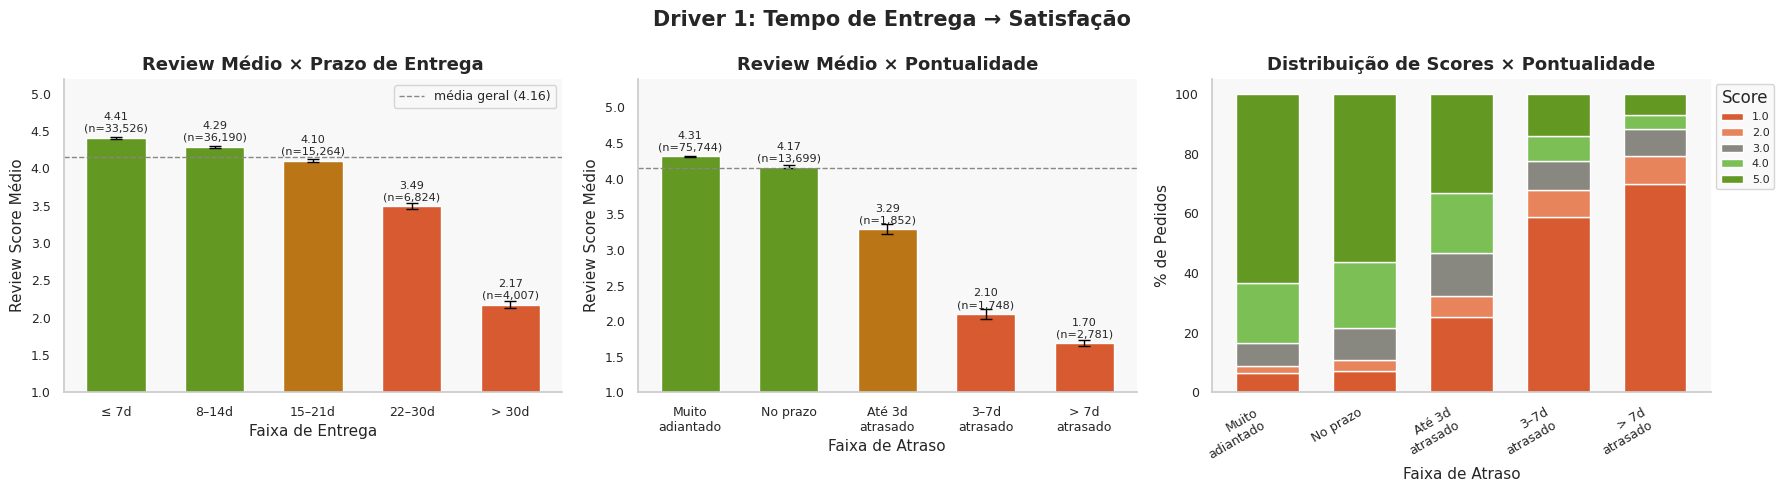

In [507]:
fig1, axes = plt.subplots(1, 3, figsize=(18, 5))
fig1.suptitle("Driver 1: Tempo de Entrega → Satisfação", fontsize=15, fontweight="bold")
 
# 1a. Review médio por faixa de entrega
ax = axes[0]
entrega_review = (
    base.groupby("faixa_entrega", observed=True)["review_score"]
    .agg(["mean", "count", "sem"])
    .reset_index()
)
cores = [CORES["positivo"], CORES["positivo"], CORES["amarelo"],
         CORES["alerta"], CORES["alerta"]]
bars = ax.bar(entrega_review["faixa_entrega"].astype(str),
              entrega_review["mean"], color=cores, edgecolor="white", width=0.6)
ax.errorbar(range(len(entrega_review)), entrega_review["mean"],
            yerr=1.96 * entrega_review["sem"], fmt="none",
            color="black", capsize=4, linewidth=1)
ax.set_ylim(1, 5.2)
ax.set_title("Review Médio × Prazo de Entrega")
ax.set_xlabel("Faixa de Entrega")
ax.set_ylabel("Review Score Médio")
ax.axhline(base["review_score"].mean(), color=CORES["neutro"],
           linestyle="--", linewidth=1, label=f"média geral ({base['review_score'].mean():.2f})")
ax.legend(fontsize=9)
for bar, row in zip(bars, entrega_review.itertuples()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.08,
            f"{row.mean:.2f}\n(n={row.count:,})", ha="center", fontsize=8)
 
# 1b. Review médio por faixa de atraso
ax2 = axes[1]
atraso_review = (
    base.groupby("faixa_atraso", observed=True)["review_score"]
    .agg(["mean", "count", "sem"])
    .reset_index()
)
cores2 = [CORES["positivo"], CORES["positivo"], CORES["amarelo"],
          CORES["alerta"], CORES["alerta"]]
bars2 = ax2.bar(atraso_review["faixa_atraso"].astype(str),
                atraso_review["mean"], color=cores2, edgecolor="white", width=0.6)
ax2.errorbar(range(len(atraso_review)), atraso_review["mean"],
             yerr=1.96 * atraso_review["sem"], fmt="none",
             color="black", capsize=4, linewidth=1)
ax2.set_ylim(1, 5.4)
ax2.set_title("Review Médio × Pontualidade")
ax2.set_xlabel("Faixa de Atraso")
ax2.set_ylabel("Review Score Médio")
ax2.axhline(base["review_score"].mean(), color=CORES["neutro"],
            linestyle="--", linewidth=1)
for bar, row in zip(bars2, atraso_review.itertuples()):
    ax2.text(bar.get_x() + bar.get_width()/2, row.mean + 0.08,
             f"{row.mean:.2f}\n(n={row.count:,})", ha="center", fontsize=8)
 
# 1c. Distribuição de scores por faixa de atraso (100% stacked)
ax3 = axes[2]
score_atraso = (
    base.dropna(subset=["faixa_atraso"])
    .groupby(["faixa_atraso", "review_score"], observed=True)
    .size()
    .unstack(fill_value=0)
)
score_atraso_pct = score_atraso.div(score_atraso.sum(axis=1), axis=0) * 100
cores_score = [CORES["alerta"], "#E8845C", CORES["neutro"],
               "#7BBF55", CORES["positivo"]]
score_atraso_pct.plot(kind="bar", stacked=True, ax=ax3,
                      color=cores_score, edgecolor="white", width=0.65)
ax3.set_title("Distribuição de Scores × Pontualidade")
ax3.set_xlabel("Faixa de Atraso")
ax3.set_ylabel("% de Pedidos")
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=30, ha="right")
ax3.legend(title="Score", bbox_to_anchor=(1, 1), fontsize=8)
 
plt.tight_layout()
fig1.savefig("driver1_entrega.png", dpi=150, bbox_inches="tight")
print("\n✓ driver1_entrega.png")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

###### Preço como Driver de Satisfação

✓ driver2_preco.png


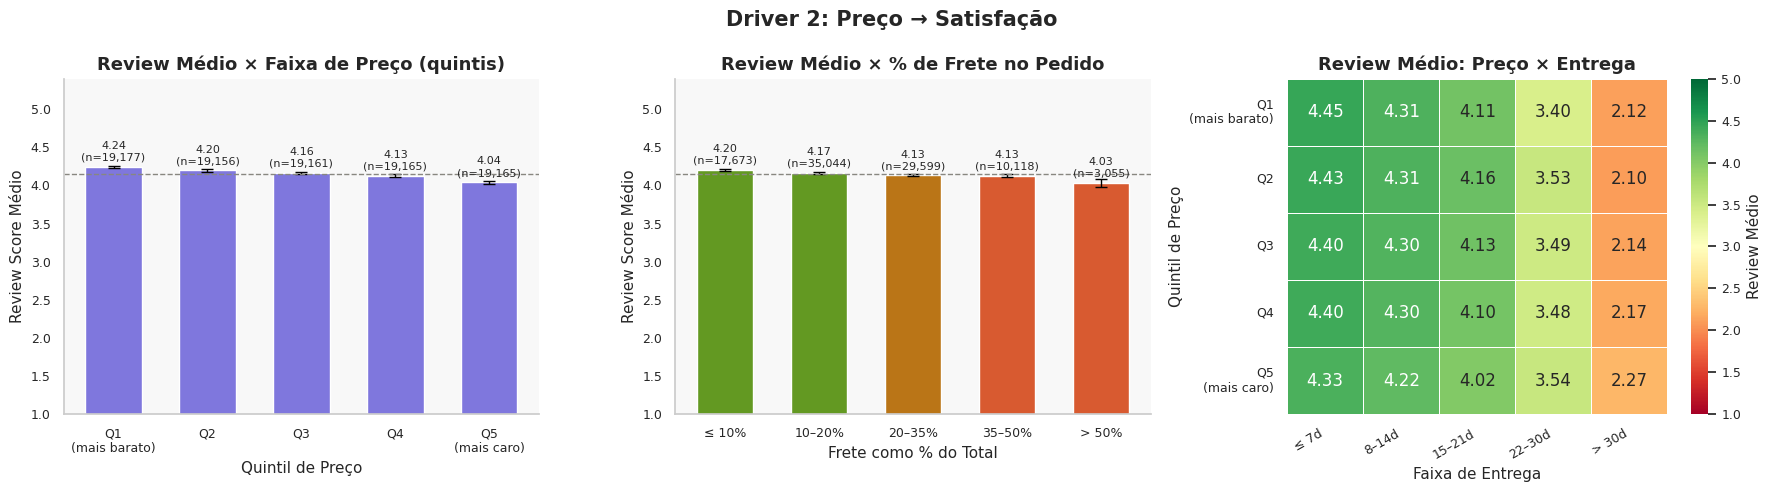

In [508]:
fig2, axes = plt.subplots(1, 3, figsize=(18, 5))
fig2.suptitle("Driver 2: Preço → Satisfação", fontsize=15, fontweight="bold")
 
# 2a. Review médio por quintil de preço
ax = axes[0]
preco_review = (
    base.groupby("faixa_preco", observed=True)["review_score"]
    .agg(["mean", "count", "sem"])
    .reset_index()
)
bars = ax.bar(preco_review["faixa_preco"].astype(str),
              preco_review["mean"],
              color=CORES["primaria"], edgecolor="white", width=0.6)
ax.errorbar(range(len(preco_review)), preco_review["mean"],
            yerr=1.96 * preco_review["sem"], fmt="none",
            color="black", capsize=4, linewidth=1)
ax.set_ylim(1, 5.4)
ax.set_title("Review Médio × Faixa de Preço (quintis)")
ax.set_xlabel("Quintil de Preço")
ax.set_ylabel("Review Score Médio")
ax.axhline(base["review_score"].mean(), color=CORES["neutro"],
           linestyle="--", linewidth=1)
 
# Limites de cada quintil
limites = base.groupby("faixa_preco", observed=True)["receita_total"].agg(["min", "max"])
for bar, row in zip(bars, preco_review.itertuples()):
    ax.text(bar.get_x() + bar.get_width()/2, row.mean + 0.08,
            f"{row.mean:.2f}\n(n={row.count:,})", ha="center", fontsize=8)
 
# 2b. Review médio por % de frete
ax2 = axes[1]
frete_review = (
    base.groupby("faixa_frete", observed=True)["review_score"]
    .agg(["mean", "count", "sem"])
    .reset_index()
)
cores_frete = [CORES["positivo"], CORES["positivo"], CORES["amarelo"],
               CORES["alerta"], CORES["alerta"]]
bars2 = ax2.bar(frete_review["faixa_frete"].astype(str),
                frete_review["mean"], color=cores_frete, edgecolor="white", width=0.6)
ax2.errorbar(range(len(frete_review)), frete_review["mean"],
             yerr=1.96 * frete_review["sem"], fmt="none",
             color="black", capsize=4, linewidth=1)
ax2.set_ylim(1, 5.4)
ax2.set_title("Review Médio × % de Frete no Pedido")
ax2.set_xlabel("Frete como % do Total")
ax2.set_ylabel("Review Score Médio")
ax2.axhline(base["review_score"].mean(), color=CORES["neutro"],
            linestyle="--", linewidth=1)
for bar, row in zip(bars2, frete_review.itertuples()):
    ax2.text(bar.get_x() + bar.get_width()/2, row.mean + 0.08,
             f"{row.mean:.2f}\n(n={row.count:,})", ha="center", fontsize=8)
 
# 2c. Heatmap: faixa de preço × faixa de entrega → review médio
ax3 = axes[2]
heatmap_data = (
    base.groupby(["faixa_preco", "faixa_entrega"], observed=True)["review_score"]
    .mean()
    .unstack()
)
sns.heatmap(
    heatmap_data,
    ax=ax3,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=1, vmax=5,
    linewidths=0.5,
    cbar_kws={"label": "Review Médio"},
)
ax3.set_title("Review Médio: Preço × Entrega")
ax3.set_xlabel("Faixa de Entrega")
ax3.set_ylabel("Quintil de Preço")
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=30, ha="right")
ax3.set_yticklabels(ax3.get_yticklabels(), rotation=0)
 
plt.tight_layout()
fig2.savefig("driver2_preco.png", dpi=150, bbox_inches="tight")
print("✓ driver2_preco.png")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

###### Painel Executivo: Importância Relativa dos Drivers

✓ driver3_painel_executivo.png

RESUMO DOS PRINCIPAIS ACHADOS

📦 ENTREGA
  Review médio — entregue no prazo: 4.29
  Review médio — entregue atrasado: 2.27
  Queda no score por atraso: 2.02 pontos
  Review médio — entrega ≤ 7 dias:  4.41
  Review médio — entrega > 21 dias: 3.01

💰 PREÇO
  Review médio — pedidos mais baratos (Q1): 4.24
  Review médio — pedidos mais caros  (Q5): 4.04
  Review médio — frete ≤ 10% do pedido: 4.21
  Review médio — frete > 35% do pedido: 4.11

🏆 DRIVER MAIS IMPACTANTE: Tempo de entrega
   |r| de Spearman = 0.235


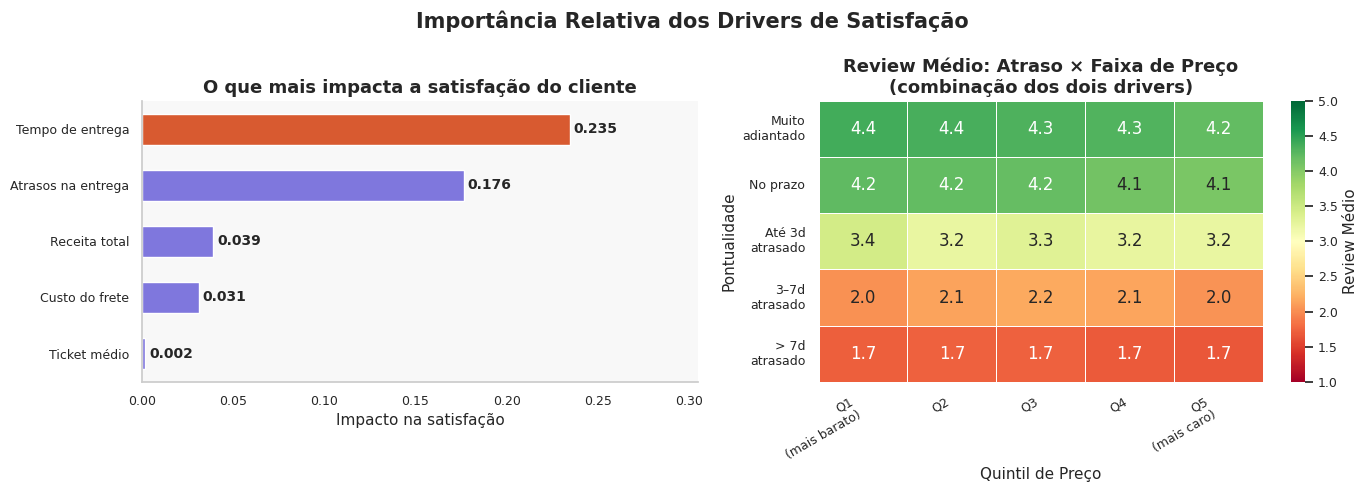

In [509]:
fig3, axes = plt.subplots(1, 2, figsize=(14, 5))
fig3.suptitle("Importância Relativa dos Drivers de Satisfação",
              fontsize=15, fontweight="bold")
 
# 3a. Correlações de Spearman (ranking visual)
ax = axes[0]
drivers = {
    "Atrasos na entrega":    abs(stats.spearmanr(base["dias_atraso"].dropna(),
                             base.loc[base["dias_atraso"].notna(), "review_score"])[0]),
    "Tempo de entrega":  abs(stats.spearmanr(base["dias_ate_entrega"].dropna(),
                             base.loc[base["dias_ate_entrega"].notna(), "review_score"])[0]),
    "Custo do frete": abs(stats.spearmanr(base["pct_frete"].dropna(),
                             base.loc[base["pct_frete"].notna(), "review_score"])[0]),
    "Receita total":     abs(stats.spearmanr(base["receita_total"].dropna(),
                             base.loc[base["receita_total"].notna(), "review_score"])[0]),
    "Ticket médio":      abs(stats.spearmanr(base["ticket_medio"].dropna(),
                             base.loc[base["ticket_medio"].notna(), "review_score"])[0]),
}
drivers_sorted = dict(sorted(drivers.items(), key=lambda x: x[1]))
cores_bar = [CORES["alerta"] if v == max(drivers.values()) else
             CORES["primaria"] for v in drivers_sorted.values()]
bars = ax.barh(list(drivers_sorted.keys()), list(drivers_sorted.values()),
               color=cores_bar, edgecolor="white", height=0.55)
ax.set_title("O que mais impacta a satisfação do cliente")
ax.set_xlabel("Impacto na satisfação")
ax.set_xlim(0, max(drivers.values()) * 1.3)
for bar, val in zip(bars, drivers_sorted.values()):
    ax.text(val + 0.002, bar.get_y() + bar.get_height()/2,
            f"{val:.3f}", va="center", fontsize=10, fontweight="bold")
 
# 3b. Score médio por combinação atraso + faixa de preço
ax2 = axes[1]
combo = (
    base.dropna(subset=["faixa_atraso", "faixa_preco"])
    .groupby(["faixa_atraso", "faixa_preco"], observed=True)["review_score"]
    .mean()
    .unstack()
)
sns.heatmap(
    combo,
    ax=ax2,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    vmin=1, vmax=5,
    linewidths=0.5,
    cbar_kws={"label": "Review Médio"},
)
ax2.set_title("Review Médio: Atraso × Faixa de Preço\n(combinação dos dois drivers)")
ax2.set_xlabel("Quintil de Preço")
ax2.set_ylabel("Pontualidade")
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=30, ha="right")
ax2.set_yticklabels(ax2.get_yticklabels(), rotation=0)
 
plt.tight_layout()
fig3.savefig("driver3_painel_executivo.png", dpi=150, bbox_inches="tight")
print("✓ driver3_painel_executivo.png")
 
# =============================================================
# RESUMO TEXTUAL AUTOMÁTICO
# =============================================================
print("\n" + "=" * 60)
print("RESUMO DOS PRINCIPAIS ACHADOS")
print("=" * 60)
 
# Queda de review por atraso
no_prazo = base[base["dias_atraso"] <= 0]["review_score"].mean()
atrasado = base[base["dias_atraso"] > 0]["review_score"].mean()
print(f"\n📦 ENTREGA")
print(f"  Review médio — entregue no prazo: {no_prazo:.2f}")
print(f"  Review médio — entregue atrasado: {atrasado:.2f}")
print(f"  Queda no score por atraso: {no_prazo - atrasado:.2f} pontos")
 
rapido = base[base["dias_ate_entrega"] <= 7]["review_score"].mean()
lento  = base[base["dias_ate_entrega"] > 21]["review_score"].mean()
print(f"  Review médio — entrega ≤ 7 dias:  {rapido:.2f}")
print(f"  Review médio — entrega > 21 dias: {lento:.2f}")
 
print(f"\n💰 PREÇO")
q1_review = base[base["faixa_preco"] == base["faixa_preco"].cat.categories[0]]["review_score"].mean()
q5_review = base[base["faixa_preco"] == base["faixa_preco"].cat.categories[-1]]["review_score"].mean()
print(f"  Review médio — pedidos mais baratos (Q1): {q1_review:.2f}")
print(f"  Review médio — pedidos mais caros  (Q5): {q5_review:.2f}")
 
frete_baixo = base[base["pct_frete"] <= 10]["review_score"].mean()
frete_alto  = base[base["pct_frete"] > 35]["review_score"].mean()
print(f"  Review médio — frete ≤ 10% do pedido: {frete_baixo:.2f}")
print(f"  Review médio — frete > 35% do pedido: {frete_alto:.2f}")
 
driver_top = max(drivers, key=drivers.get)
print(f"\n🏆 DRIVER MAIS IMPACTANTE: {driver_top}")
print(f"   |r| de Spearman = {drivers[driver_top]:.3f}")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

In [510]:
print(rfm.columns)

Index(['customer_id', 'ultima_compra', 'frequencia', 'primeiro_pedido',
       'recencia_dias', 'valor_total', 'ticket_medio', 'lifetime_dias',
       'r_score', 'f_score', 'm_score', 'rfm_score', 'risco_recencia',
       'risco_frequencia', 'risco_valor', 'review_medio', 'risco_review',
       'churn_score', 'segmento', 'nivel_risco'],
      dtype='str')


In [511]:
CORES = {
    "primaria":   "#7F77DD",
    "secundaria": "#1D9E75",
    "alerta":     "#D85A30",
    "neutro":     "#888780",
    "positivo":   "#639922",
    "amarelo":    "#BA7517",
}
 
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({
    "figure.facecolor":  "white",
    "axes.facecolor":    "#F8F8F8",
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.titlesize":    13,
    "axes.titleweight":  "bold",
    "axes.labelsize":    11,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
})

In [512]:
# Carregar dados 
fact  = pd.read_csv("fact_orders.csv", parse_dates=["order_purchase_timestamp"])
orders = pd.read_csv("olist_orders_dataset.csv",     parse_dates=["order_purchase_timestamp"])
 
# Data de referência = último dia da base + 1 dia
DATA_REF = orders["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
print(f"Data de referência: {DATA_REF.date()}")
 
# Apenas pedidos entregues
entregues = orders[orders["order_status"] == "delivered"].copy()

Data de referência: 2018-10-18


In [513]:
# BASE RFM — 1 LINHA POR CLIENTE
rfm = (
    entregues
    .groupby("customer_id")
    .agg(
        ultima_compra  = ("order_purchase_timestamp", "max"),
        frequencia     = ("order_id", "count"),
        primeiro_pedido= ("order_purchase_timestamp", "min"),
    )
    .reset_index()
)
 
# Recência: dias desde a última compra
rfm["recencia_dias"] = (DATA_REF - rfm["ultima_compra"]).dt.days
 
# Valor monetário: join com fact_orders
valor = (
    fact[fact["order_status"] == "delivered"]
    .groupby("customer_id")["receita_total"]
    .sum()
    .reset_index()
    .rename(columns={"receita_total": "valor_total"})
)
rfm = rfm.merge(valor, on="customer_id", how="left")
rfm["ticket_medio"] = rfm["valor_total"] / rfm["frequencia"]
 
# Tempo de vida do cliente (dias entre 1ª e última compra)
rfm["lifetime_dias"] = (rfm["ultima_compra"] - rfm["primeiro_pedido"]).dt.days
 
print(f"Total de clientes: {len(rfm):,}")
print(f"Clientes com 2+ compras: {(rfm['frequencia'] >= 2).sum():,}")

Total de clientes: 96,478
Clientes com 2+ compras: 0


In [514]:
## SCORES RFM (1-5, sendo 5 o melhor)
# Recência: menor = melhor → score invertido
rfm["r_score"] = pd.qcut(rfm["recencia_dias"], q=5,
                          labels=[5, 4, 3, 2, 1]).astype(int)
 
# Frequência: maior = melhor
rfm["f_score"] = pd.qcut(rfm["frequencia"].rank(method="first"), q=5,
                          labels=[1, 2, 3, 4, 5]).astype(int)
 
# Monetário: maior = melhor
rfm["m_score"] = pd.qcut(rfm["valor_total"].rank(method="first"), q=5,
                          labels=[1, 2, 3, 4, 5]).astype(int)
 
rfm["rfm_score"] = rfm["r_score"] + rfm["f_score"] + rfm["m_score"]


###### Score risco de churn

In [515]:
print(rfm.columns)

Index(['customer_id', 'ultima_compra', 'frequencia', 'primeiro_pedido',
       'recencia_dias', 'valor_total', 'ticket_medio', 'lifetime_dias',
       'r_score', 'f_score', 'm_score', 'rfm_score'],
      dtype='str')


In [516]:
# FUNÇÃO AUXILIAR: normalização segura (evita divisão por zero)
# ============================================================
def normalizar(series, inverter=False):
    """
    Normaliza uma série para [0, 1].
    Se min == max (variância zero), retorna 0.5 para todos.
    Se inverter=True, valores altos viram risco baixo.
    """
    minv, maxv = series.min(), series.max()
    if maxv == minv:
        print(f"  ⚠️  Coluna '{series.name}' sem variação (min=max={minv}). Usando 0.5.")
        return pd.Series(0.5, index=series.index)
    norm = (series - minv) / (maxv - minv)
    return (1 - norm) if inverter else norm

# ============================================================
# a) Recência — mais antigo = maior risco
# ============================================================
rfm["risco_recencia"] = normalizar(rfm["recencia_dias"], inverter=False)

# ============================================================
# b) Frequência — menor = maior risco (invertida)
# ============================================================
rfm["risco_frequencia"] = normalizar(rfm["frequencia"], inverter=True)

# ============================================================
# c) Valor — menor = maior risco (invertido)
# ============================================================
rfm["risco_valor"] = normalizar(rfm["valor_total"], inverter=True)

# ============================================================
# d) Review — ruim = maior risco
#    Merge seguro: remove coluna duplicada antes de fazer join
# ============================================================

# Remove coluna antiga se já existir (evita sufixo _x/_y)
for col in ["review_medio", "review_medio_x", "review_medio_y"]:
    if col in rfm.columns:
        rfm.drop(columns=col, inplace=True)

review_cliente = (
    fact[fact["order_status"] == "delivered"]
    .groupby("customer_id", as_index=False)["review_score"]
    .mean()
    .rename(columns={"review_score": "review_medio"})
)

rfm = rfm.merge(review_cliente, on="customer_id", how="left")

rfm["risco_review"] = rfm["review_medio"].apply(
    lambda s: 0.5 if pd.isna(s) else round((5 - s) / 4, 4)
)

# ============================================================
# Score final ponderado
# ============================================================
PESO_RECENCIA   = 0.40
PESO_FREQUENCIA = 0.25
PESO_VALOR      = 0.20
PESO_REVIEW     = 0.15

rfm["churn_score"] = (
    rfm["risco_recencia"]    * PESO_RECENCIA   +
    rfm["risco_frequencia"]  * PESO_FREQUENCIA +
    rfm["risco_valor"]       * PESO_VALOR      +
    rfm["risco_review"]      * PESO_REVIEW
).round(4)

# ============================================================
# Diagnóstico rápido — confirma que não há NaN
# ============================================================
colunas_risco = [
    "risco_recencia", "risco_frequencia",
    "risco_valor", "risco_review", "churn_score"
]
print("\n=== DIAGNÓSTICO PÓS-CÁLCULO ===")
print(rfm[colunas_risco].isnull().sum().rename("NaNs"))
print()
print(rfm[colunas_risco].describe().round(3))

  ⚠️  Coluna 'frequencia' sem variação (min=max=1). Usando 0.5.

=== DIAGNÓSTICO PÓS-CÁLCULO ===
risco_recencia      0
risco_frequencia    0
risco_valor         0
risco_review        0
churn_score         0
Name: NaNs, dtype: int64

       risco_recencia  risco_frequencia  risco_valor  risco_review  \
count       96478.000           96478.0    96478.000     96478.000   
mean            0.336               0.5        0.989         0.213   
std             0.214               0.0        0.016         0.321   
min             0.000               0.5        0.000         0.000   
25%             0.161               0.5        0.988         0.000   
50%             0.309               0.5        0.993         0.000   
75%             0.489               0.5        0.996         0.250   
max             1.000               0.5        1.000         1.000   

       churn_score  
count    96478.000  
mean         0.489  
std          0.099  
min          0.273  
25%          0.409  
50%       

In [517]:
#SEGMENTAÇÃO DE RISCO
def segmento_rfm(row):
    r, f, m = row["r_score"], row["f_score"], row["m_score"]
    score = row["rfm_score"]
    if r >= 4 and f >= 4 and m >= 4:
        return "Campeão"
    elif r >= 4 and f >= 3:
        return "Fiel"
    elif r >= 3 and f <= 2:
        return "Promissor"
    elif r <= 2 and f >= 3:
        return "Em risco"
    elif r == 1 and score <= 6:
        return "Perdido"
    elif r <= 2 and f <= 2:
        return "Hibernando"
    else:
        return "Precisando atenção"
 
rfm["segmento"] = rfm.apply(segmento_rfm, axis=1)
 
# Nível de risco de churn
rfm["nivel_risco"] = pd.cut(
    rfm["churn_score"],
    bins=[0, 0.35, 0.55, 0.75, 1.0],
    labels=["Baixo", "Médio", "Alto", "Crítico"],
    include_lowest=True,
)

rfm["churn_score"].dropna()

rfm["churn_score"].head()
rfm["churn_score"].describe()

count    96478.000000
mean         0.488985
std          0.098624
min          0.273100
25%          0.408700
50%          0.480700
75%          0.560500
max          0.873000
Name: churn_score, dtype: float64

In [518]:
# Diagnostico Churn 
print("\n=== DISTRIBUIÇÃO DE SEGMENTOS RFM ===")
seg_counts = rfm["segmento"].value_counts()
for seg, n in seg_counts.items():
    pct = n / len(rfm) * 100
    print(f"  {seg:<22} {n:>6,}  ({pct:.1f}%)")
 
print("\n=== DISTRIBUIÇÃO DE NÍVEL DE RISCO ===")
risco_counts = rfm["nivel_risco"].value_counts().sort_index()
for nivel, n in risco_counts.items():
    pct = n / len(rfm) * 100
    print(f"  {nivel:<10} {n:>6,}  ({pct:.1f}%)")


=== DISTRIBUIÇÃO DE SEGMENTOS RFM ===
  Promissor              23,275  (24.1%)
  Em risco               23,266  (24.1%)
  Fiel                   16,770  (17.4%)
  Precisando atenção     11,492  (11.9%)
  Hibernando              9,933  (10.3%)
  Campeão                 6,359  (6.6%)
  Perdido                 5,383  (5.6%)

=== DISTRIBUIÇÃO DE NÍVEL DE RISCO ===
  Baixo       7,008  (7.3%)
  Médio      62,273  (64.5%)
  Alto       26,530  (27.5%)
  Crítico       667  (0.7%)


In [519]:
rfm[[
    "risco_recencia",
    "risco_frequencia",
    "risco_valor",
    "risco_review",
    "churn_score"
]].isna().sum()

risco_recencia      0
risco_frequencia    0
risco_valor         0
risco_review        0
churn_score         0
dtype: int64

###### Visão geral dos segmentos 

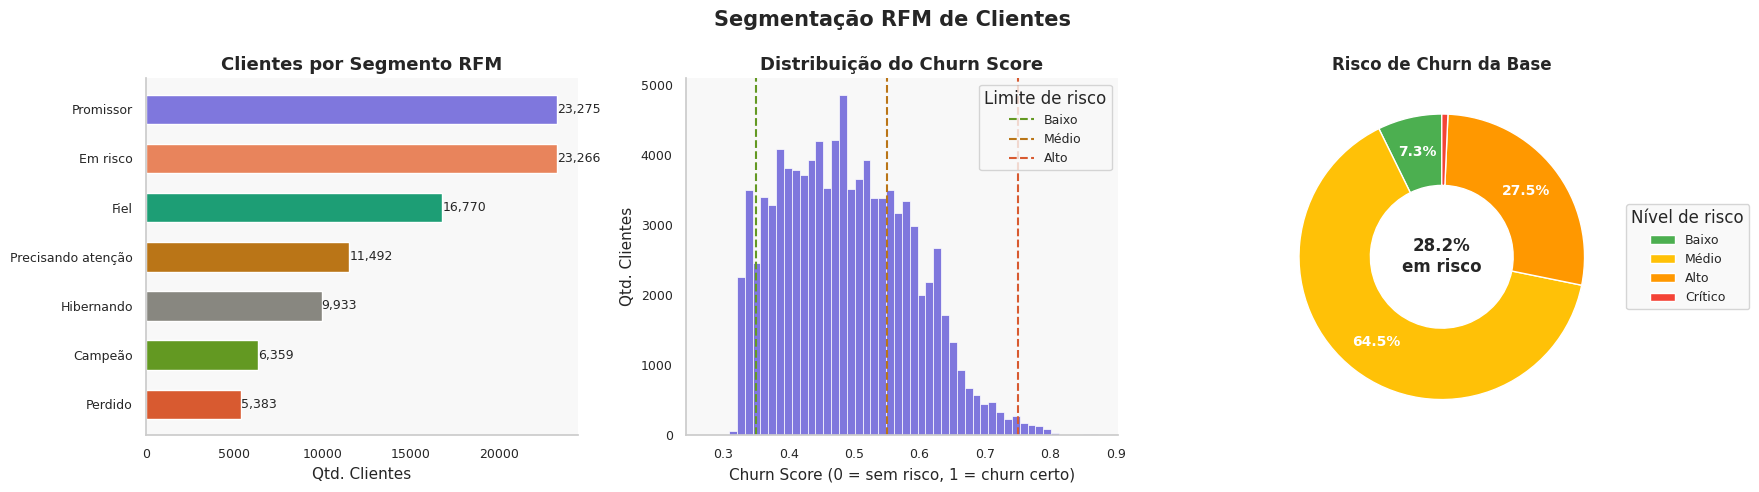

In [542]:
fig1, axes = plt.subplots(1, 3, figsize=(18, 5))
fig1.suptitle("Segmentação RFM de Clientes", fontsize=15, fontweight="bold")
 
# 1a. Distribuição de segmentos
ax = axes[0]
seg_sorted = rfm["segmento"].value_counts()
cores_seg = {
    "Campeão":           CORES["positivo"],
    "Fiel":              CORES["secundaria"],
    "Promissor":         CORES["primaria"],
    "Precisando atenção":CORES["amarelo"],
    "Em risco":          "#E8845C",
    "Hibernando":        CORES["neutro"],
    "Perdido":           CORES["alerta"],
}
bars = ax.barh(seg_sorted.index[::-1], seg_sorted.values[::-1],
               color=[cores_seg.get(s, CORES["neutro"]) for s in seg_sorted.index[::-1]],
               edgecolor="white", height=0.6)
ax.set_title("Clientes por Segmento RFM")
ax.set_xlabel("Qtd. Clientes")
for bar, val in zip(bars, seg_sorted.values[::-1]):
    ax.text(val + 5, bar.get_y() + bar.get_height()/2,
            f"{val:,}", va="center", fontsize=9)
 
# 1b. Distribuição do churn score
ax2 = axes[1]
ax2.hist(rfm["churn_score"], bins=50, color=CORES["primaria"],
         edgecolor="white", linewidth=0.5)
for limite, cor, label in [
    (0.35, CORES["positivo"],  "Baixo"),
    (0.55, CORES["amarelo"],   "Médio"),
    (0.75, CORES["alerta"],    "Alto"),
]:
    ax2.axvline(limite, color=cor, linestyle="--", linewidth=1.5, label=label)
ax2.set_title("Distribuição do Churn Score")
ax2.set_xlabel("Churn Score (0 = sem risco, 1 = churn certo)")
ax2.set_ylabel("Qtd. Clientes")
ax2.legend(title="Limite de risco", fontsize=9)
 
# 1c. Nível de risco: donut

ax3 = axes[2]

# Dados
risco_vals = rfm["nivel_risco"].value_counts().sort_index()

# Cores
cores_risco = ["#4CAF50", "#FFC107", "#FF9800", "#F44336"]

# Função para mostrar % apenas (sem poluir)
def autopct_format(pct):
    return f"{pct:.1f}%" if pct > 3 else ""

wedges, texts, autotexts = ax3.pie(
    risco_vals.values,
    labels=None,  # remove labels externos
    autopct=autopct_format,
    colors=cores_risco,
    startangle=90,
    wedgeprops={"width": 0.5, "edgecolor": "white"},
    pctdistance=0.75,  # 🔥 posiciona o texto no meio da fatia
    textprops={"fontsize": 10, "color": "white", "weight": "bold"},
)

# Legenda externa (limpa e organizada)
ax3.legend(
    wedges,
    risco_vals.index,
    title="Nível de risco",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=9
)

# Texto central (insight)
total = risco_vals.sum()
risco_alto = risco_vals.get("Alto", 0) + risco_vals.get("Crítico", 0)
pct_risco = risco_alto / total * 100

ax3.text(
    0, 0,
    f"{pct_risco:.1f}%\nem risco",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold"
)

# Título
ax3.set_title("Risco de Churn da Base", fontsize=12, fontweight="bold")

plt.tight_layout()
# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)
 

###### Analise dos componentes de risco

✓ churn_fig2_componentes.png


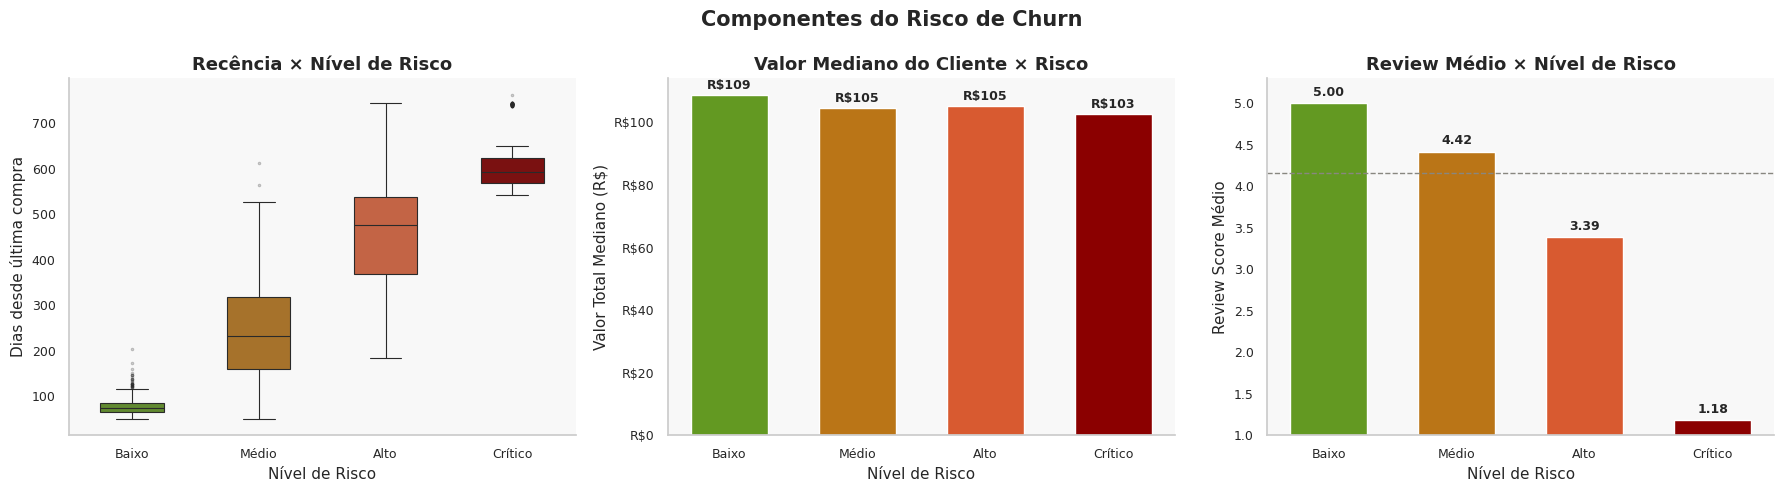

In [521]:
fig2, axes = plt.subplots(1, 3, figsize=(18, 5))
fig2.suptitle("Componentes do Risco de Churn", fontsize=15, fontweight="bold")
 
# 2a. Recência por nível de risco
ax = axes[0]
ordem = ["Baixo", "Médio", "Alto", "Crítico"]
sns.boxplot(
    data=rfm, x="nivel_risco", y="recencia_dias",
    order=ordem, palette=[CORES["positivo"], CORES["amarelo"],
                           CORES["alerta"], "#8B0000"],
    ax=ax, width=0.5, linewidth=0.8,
    flierprops={"marker": ".", "markersize": 3, "alpha": 0.3},
)
ax.set_title("Recência × Nível de Risco")
ax.set_xlabel("Nível de Risco")
ax.set_ylabel("Dias desde última compra")
 
# 2b. Valor total por nível de risco
ax2 = axes[1]
valor_risco = rfm.groupby("nivel_risco", observed=True)["valor_total"].median()
bars = ax2.bar(
    ordem,
    [valor_risco.get(n, 0) for n in ordem],
    color=[CORES["positivo"], CORES["amarelo"], CORES["alerta"], "#8B0000"],
    edgecolor="white", width=0.6,
)
ax2.set_title("Valor Mediano do Cliente × Risco")
ax2.set_xlabel("Nível de Risco")
ax2.set_ylabel("Valor Total Mediano (R$)")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R${x:,.0f}"))
for bar, nivel in zip(bars, ordem):
    val = valor_risco.get(nivel, 0)
    ax2.text(bar.get_x() + bar.get_width()/2, val + 1,
             f"R${val:,.0f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
 
# 2c. Review médio por nível de risco
ax3 = axes[2]
review_risco = rfm.groupby("nivel_risco", observed=True)["review_medio"].mean()
bars3 = ax3.bar(
    ordem,
    [review_risco.get(n, 0) for n in ordem],
    color=[CORES["positivo"], CORES["amarelo"], CORES["alerta"], "#8B0000"],
    edgecolor="white", width=0.6,
)
ax3.set_ylim(1, 5.3)
ax3.set_title("Review Médio × Nível de Risco")
ax3.set_xlabel("Nível de Risco")
ax3.set_ylabel("Review Score Médio")
ax3.axhline(rfm["review_medio"].mean(), color=CORES["neutro"],
            linestyle="--", linewidth=1)
for bar, nivel in zip(bars3, ordem):
    val = review_risco.get(nivel, 0)
    if val > 0:
        ax3.text(bar.get_x() + bar.get_width()/2, val + 0.05,
                 f"{val:.2f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
 
plt.tight_layout()
fig2.savefig("churn_fig2_componentes.png", dpi=150, bbox_inches="tight")
print("✓ churn_fig2_componentes.png")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

###### Mapa RFM (Recência × Frequência)

###### EXPORTAR LISTA DE CLIENTES EM RISCO

In [522]:
colunas_export = [
    "customer_id",
    "nivel_risco",
    "churn_score",
    "segmento",
    "recencia_dias",
    "frequencia",
    "valor_total",
    "ticket_medio",
    "review_medio",
    "ultima_compra",
    "r_score", "f_score", "m_score", "rfm_score",
]
 
# Lista completa ordenada por risco
lista_completa = (
    rfm[colunas_export]
    .sort_values("churn_score", ascending=False)
    .reset_index(drop=True)
)
lista_completa.to_csv("clientes_churn_score.csv", index=False)
print("\n✓ clientes_churn_score.csv  — todos os clientes com score")
 
# Lista prioritária: apenas Alto + Crítico
lista_risco = lista_completa[
    lista_completa["nivel_risco"].isin(["Alto", "Crítico"])
].copy()
lista_risco.to_csv("clientes_em_risco.csv", index=False)
 
print(f"✓ clientes_em_risco.csv     — {len(lista_risco):,} clientes Alto/Crítico")
 


✓ clientes_churn_score.csv  — todos os clientes com score
✓ clientes_em_risco.csv     — 27,197 clientes Alto/Crítico


##### Resumo Executivo 

In [523]:
print("\n" + "=" * 60)
print("RESUMO EXECUTIVO — RISCO DE CHURN")
print("=" * 60)
 
criticos = rfm[rfm["nivel_risco"] == "Crítico"]
altos    = rfm[rfm["nivel_risco"] == "Alto"]
 
print(f"\n🚨 CRÍTICO  : {len(criticos):,} clientes")
print(f"   Recência média : {criticos['recencia_dias'].mean():.0f} dias sem comprar")
print(f"   Valor médio    : R${criticos['valor_total'].mean():,.2f}")
print(f"   Review médio   : {criticos['review_medio'].mean():.2f}")
 
print(f"\n⚠️  ALTO     : {len(altos):,} clientes")
print(f"   Recência média : {altos['recencia_dias'].mean():.0f} dias sem comprar")
print(f"   Valor médio    : R${altos['valor_total'].mean():,.2f}")
print(f"   Review médio   : {altos['review_medio'].mean():.2f}")
 
receita_risco = lista_risco["valor_total"].sum()
print(f"\n💰 Receita histórica em risco: R${receita_risco:,.2f}")
print(f"   ({receita_risco / rfm['valor_total'].sum() * 100:.1f}% da receita total da base)")


RESUMO EXECUTIVO — RISCO DE CHURN

🚨 CRÍTICO  : 667 clientes
   Recência média : 607 dias sem comprar
   Valor médio    : R$156.57
   Review médio   : 1.18

⚠️  ALTO     : 26,530 clientes
   Recência média : 454 dias sem comprar
   Valor médio    : R$158.51
   Review médio   : 3.39

💰 Receita histórica em risco: R$4,309,609.01
   (27.9% da receita total da base)


In [524]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

CORES = {
    "primaria":   "#7F77DD",
    "secundaria": "#1D9E75",
    "alerta":     "#D85A30",
    "neutro":     "#888780",
    "positivo":   "#639922",
    "amarelo":    "#BA7517",
    "critico":    "#8B0000",
}
 
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({
    "figure.facecolor":  "white",
    "axes.facecolor":    "#F8F8F8",
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.titlesize":    13,
    "axes.titleweight":  "bold",
    "axes.labelsize":    11,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
})

In [525]:
# CARREGAR DADOS

fact = pd.read_csv("fact_orders.csv", parse_dates=[
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
])
 
base = fact[
    (fact["order_status"] == "delivered") &
    (fact["dias_ate_entrega"].notna()) &
    (fact["receita_total"].notna())
].copy()
 
# % frete
base["pct_frete"] = (base["receita_frete"] / base["receita_total"] * 100).clip(0, 100)
 
# Faixas
base["faixa_entrega"] = pd.cut(
    base["dias_ate_entrega"],
    bins=[0, 7, 14, 21, 30, 999],
    labels=["≤ 7d", "8–14d", "15–21d", "22–30d", "> 30d"],
)
base["faixa_preco"] = pd.qcut(
    base["receita_total"], q=5,
    labels=["Q1\nMais barato", "Q2", "Q3", "Q4", "Q5\nMais caro"],
    duplicates="drop",
)
base["faixa_frete"] = pd.cut(
    base["pct_frete"],
    bins=[0, 10, 20, 35, 50, 100],
    labels=["≤ 10%", "10–20%", "20–35%", "35–50%", "> 50%"],
)
 
print(f"Base: {len(base):,} pedidos entregues")

Base: 96,470 pedidos entregues


###### CÁLCULOS BASE PARA RECOMENDAÇÕES

In [526]:
# --- Entrega ---
media_entrega       = base["dias_ate_entrega"].mean()
mediana_entrega     = base["dias_ate_entrega"].median()
pct_acima_21        = (base["dias_ate_entrega"] > 21).mean() * 100
pct_atrasado        = (base["dias_atraso"] > 0).mean() * 100
review_pontual      = base[base["dias_atraso"] <= 0]["review_score"].mean()
review_atrasado     = base[base["dias_atraso"] > 0]["review_score"].mean()
queda_review_atraso = review_pontual - review_atrasado
 
# --- Frete ---
media_frete_pct     = base["pct_frete"].mean()
mediana_frete_pct   = base["pct_frete"].median()
pct_frete_alto      = (base["pct_frete"] > 35).mean() * 100
review_frete_baixo  = base[base["pct_frete"] <= 10]["review_score"].mean()
review_frete_alto   = base[base["pct_frete"] > 35]["review_score"].mean()
 
# --- Preço ---
q1_limite = base["receita_total"].quantile(0.20)
q5_limite = base["receita_total"].quantile(0.80)
review_q1 = base[base["receita_total"] <= q1_limite]["review_score"].mean()
review_q5 = base[base["receita_total"] >= q5_limite]["review_score"].mean()
ticket_medio_geral  = base["receita_total"].mean()
ticket_mediano      = base["receita_total"].median()

###### ENTREGA: onde estão as perdas?

✓ melhoria_fig1_entrega.png


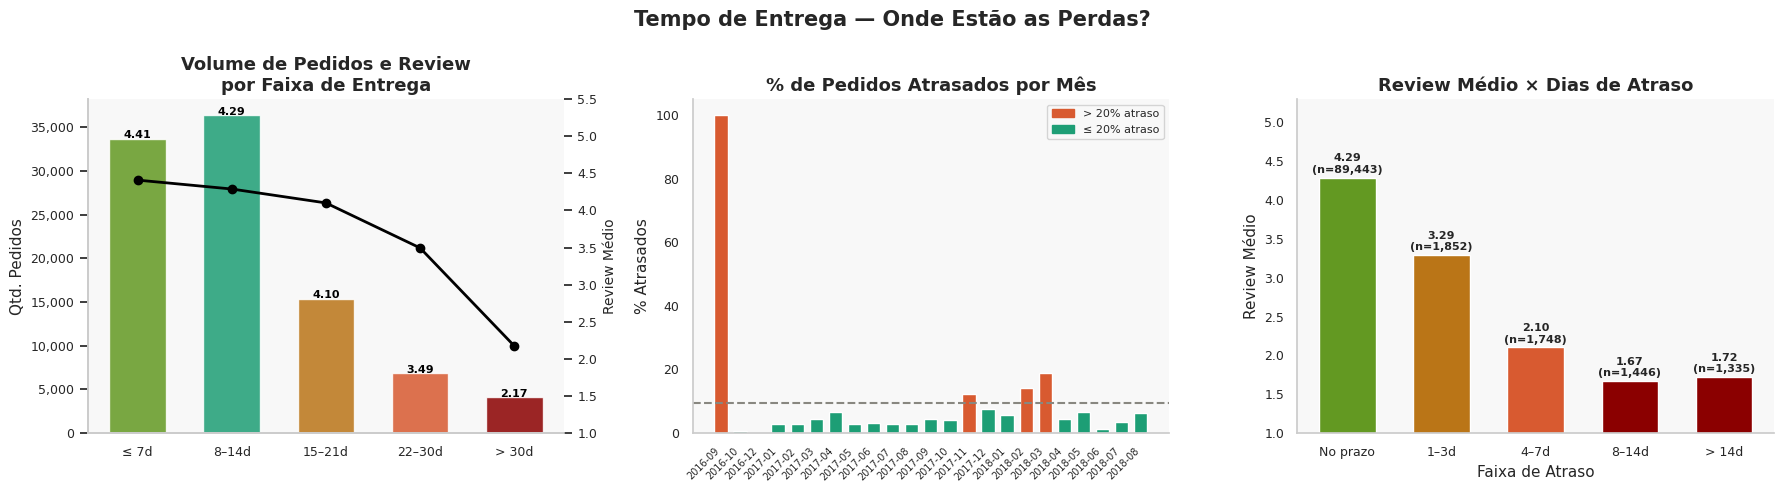

In [538]:
fig1, axes = plt.subplots(1, 3, figsize=(18, 5))
fig1.suptitle("Tempo de Entrega — Onde Estão as Perdas?",
              fontsize=15, fontweight="bold")
 
# 1a. Volume e review médio por faixa de entrega (eixo duplo)
ax = axes[0]
entrega_stats = (
    base.groupby("faixa_entrega", observed=True)
    .agg(pedidos=("order_id", "count"), review=("review_score", "mean"))
    .reset_index()
)
x = range(len(entrega_stats))
cores_e = [CORES["positivo"], CORES["secundaria"], CORES["amarelo"],
           CORES["alerta"], CORES["critico"]]
bars = ax.bar(x, entrega_stats["pedidos"], color=cores_e, edgecolor="white",
              width=0.6, alpha=0.85)
ax2r = ax.twinx()
ax2r.plot(x, entrega_stats["review"], color="black", marker="o",
          linewidth=2, markersize=6, zorder=5)
ax2r.set_ylim(1, 5.5)
ax2r.set_ylabel("Review Médio", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(entrega_stats["faixa_entrega"].astype(str))
ax.set_title("Volume de Pedidos e Review\npor Faixa de Entrega")
ax.set_ylabel("Qtd. Pedidos")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
for bar, row in zip(bars, entrega_stats.itertuples()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            f"{row.review:.2f}", ha="center", fontsize=8, color="black", fontweight="bold")
 
# 1b. Percentual de pedidos atrasados por mês
ax3 = axes[1]
base["mes"] = base["order_purchase_timestamp"].dt.to_period("M").astype(str)
atraso_mes = (
    base.dropna(subset=["dias_atraso"])
    .groupby("mes")
    .apply(lambda g: pd.Series({
        "pct_atraso": (g["dias_atraso"] > 0).mean() * 100,
        "n": len(g),
    }))
    .reset_index()
)
cores_barras = [CORES["alerta"] if v > 10 else CORES["secundaria"]
                for v in atraso_mes["pct_atraso"]]
ax3.bar(range(len(atraso_mes)), atraso_mes["pct_atraso"],
        color=cores_barras, edgecolor="white", width=0.7)
ax3.axhline(atraso_mes["pct_atraso"].mean(), color=CORES["neutro"],
            linestyle="--", linewidth=1.5,
            label=f"média {atraso_mes['pct_atraso'].mean():.1f}%")
ax3.set_xticks(range(len(atraso_mes)))
ax3.set_xticklabels(atraso_mes["mes"], rotation=45, ha="right", fontsize=7)
ax3.set_title("% de Pedidos Atrasados por Mês")
ax3.set_ylabel("% Atrasados")
ax3.legend(fontsize=9)
patch_alerta = mpatches.Patch(color=CORES["alerta"], label="> 20% atraso")
patch_ok     = mpatches.Patch(color=CORES["secundaria"], label="≤ 20% atraso")
ax3.legend(handles=[patch_alerta, patch_ok], fontsize=8)
 
# 1c. Custo do atraso em receita (pedidos atrasados × review perdido)
ax4 = axes[2]
impacto = (
    base.dropna(subset=["dias_atraso", "review_score"])
    .assign(faixa=lambda d: pd.cut(
        d["dias_atraso"],
        bins=[-999, 0, 3, 7, 14, 999],
        labels=["No prazo", "1–3d", "4–7d", "8–14d", "> 14d"]
    ))
    .groupby("faixa", observed=True)
    .agg(
        n=("order_id", "count"),
        review_medio=("review_score", "mean"),
        receita_media=("receita_total", "mean"),
    )
    .reset_index()
)
cores_imp = [CORES["positivo"], CORES["amarelo"], CORES["alerta"],
             CORES["critico"], CORES["critico"]]
bars4 = ax4.bar(impacto["faixa"].astype(str), impacto["review_medio"],
                color=cores_imp, edgecolor="white", width=0.6)
ax4.set_ylim(1, 5.3)
ax4.set_title("Review Médio × Dias de Atraso")
ax4.set_xlabel("Faixa de Atraso")
ax4.set_ylabel("Review Médio")
for bar, row in zip(bars4, impacto.itertuples()):
    ax4.text(bar.get_x() + bar.get_width()/2, row.review_medio + 0.06,
             f"{row.review_medio:.2f}\n(n={row.n:,})",
             ha="center", fontsize=8, fontweight="bold")
 
plt.tight_layout()
fig1.savefig("melhoria_fig1_entrega.png", dpi=150, bbox_inches="tight")
print("✓ melhoria_fig1_entrega.png")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

###### FRETE: impacto e oportunidade

✓ melhoria_fig2_frete.png


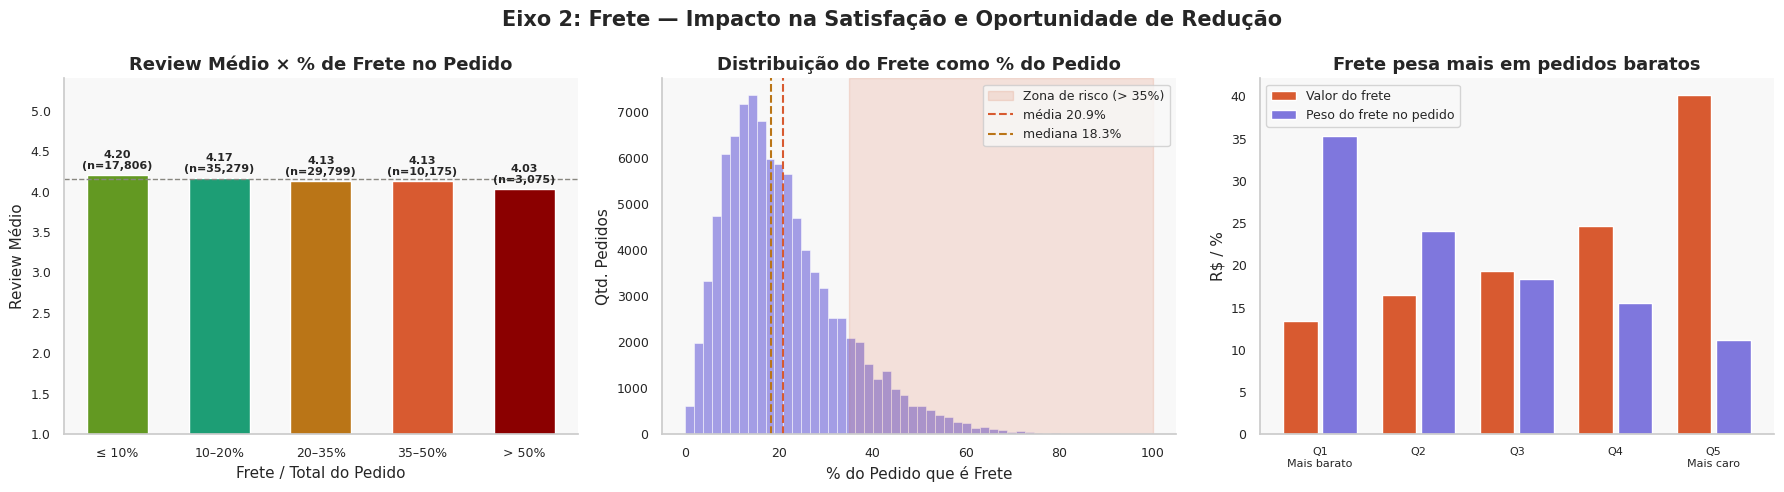

In [536]:
fig2, axes = plt.subplots(1, 3, figsize=(18, 5))
fig2.suptitle("Eixo 2: Frete — Impacto na Satisfação e Oportunidade de Redução",
              fontsize=15, fontweight="bold")
 
# 2a. Review por faixa de frete
ax = axes[0]
frete_stats = (
    base.groupby("faixa_frete", observed=True)
    .agg(n=("order_id", "count"), review=("review_score", "mean"))
    .reset_index()
)
cores_f = [CORES["positivo"], CORES["secundaria"], CORES["amarelo"],
           CORES["alerta"], CORES["critico"]]
bars = ax.bar(frete_stats["faixa_frete"].astype(str), frete_stats["review"],
              color=cores_f, edgecolor="white", width=0.6)
ax.set_ylim(1, 5.4)
ax.set_title("Review Médio × % de Frete no Pedido")
ax.set_xlabel("Frete / Total do Pedido")
ax.set_ylabel("Review Médio")
ax.axhline(base["review_score"].mean(), color=CORES["neutro"],
           linestyle="--", linewidth=1)
for bar, row in zip(bars, frete_stats.itertuples()):
    ax.text(bar.get_x() + bar.get_width()/2, row.review + 0.07,
            f"{row.review:.2f}\n(n={row.n:,})",
            ha="center", fontsize=8, fontweight="bold")
 
# 2b. Distribuição de % frete com zona de risco destacada
ax2 = axes[1]
ax2.hist(base["pct_frete"].dropna(), bins=50,
         color=CORES["primaria"], edgecolor="white", linewidth=0.5, alpha=0.7)
ax2.axvspan(35, 100, color=CORES["alerta"], alpha=0.15, label="Zona de risco (> 35%)")
ax2.axvline(media_frete_pct, color=CORES["alerta"], linestyle="--",
            linewidth=1.5, label=f"média {media_frete_pct:.1f}%")
ax2.axvline(mediana_frete_pct, color=CORES["amarelo"], linestyle="--",
            linewidth=1.5, label=f"mediana {mediana_frete_pct:.1f}%")
ax2.set_title("Distribuição do Frete como % do Pedido")
ax2.set_xlabel("% do Pedido que é Frete")
ax2.set_ylabel("Qtd. Pedidos")
ax2.legend(fontsize=9)
 
# 2c. Frete médio absoluto por faixa de preço
ax3 = axes[2]
frete_preco = (
    base.groupby("faixa_preco", observed=True)
    .agg(
        frete_medio=("receita_frete", "mean"),
        receita_media=("receita_total", "mean"),
        pct_frete_medio=("pct_frete", "mean"),
    )
    .reset_index()
)
x = range(len(frete_preco))
b1 = ax3.bar([i - 0.2 for i in x], frete_preco["frete_medio"],
             width=0.35, color=CORES["alerta"], label="Valor do frete",
             edgecolor="white")
b2 = ax3.bar([i + 0.2 for i in x], frete_preco["pct_frete_medio"],
             width=0.35, color=CORES["primaria"], label="Peso do frete no pedido",
             edgecolor="white")
ax3.set_xticks(x)
ax3.set_xticklabels(frete_preco["faixa_preco"].astype(str), fontsize=8)
ax3.set_title("Frete pesa mais em pedidos baratos")
ax3.set_ylabel("R$ / %")
ax3.legend(fontsize=9)
 
plt.tight_layout()
fig2.savefig("melhoria_fig2_frete.png", dpi=150, bbox_inches="tight")
print("✓ melhoria_fig2_frete.png")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

###### PREÇO: faixas de melhor e pior performance

✓ melhoria_fig3_preco.png


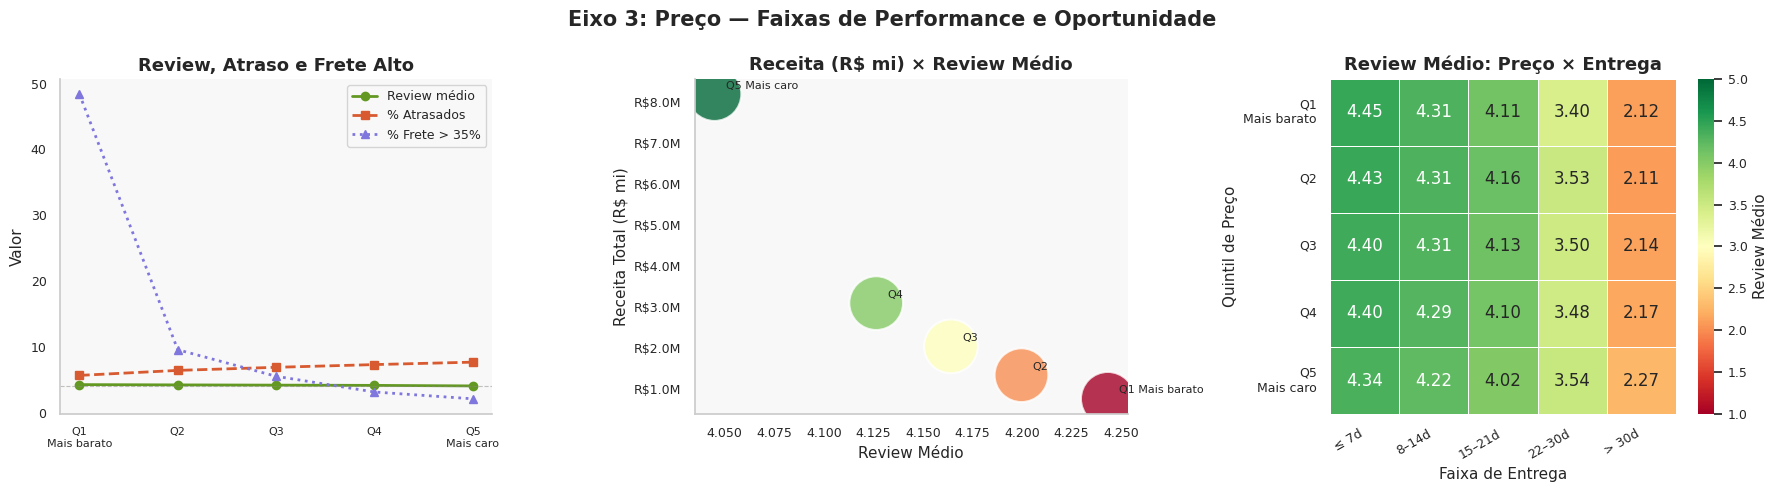

In [537]:
fig3, axes = plt.subplots(1, 3, figsize=(18, 5))
fig3.suptitle("Eixo 3: Preço — Faixas de Performance e Oportunidade",
              fontsize=15, fontweight="bold")
 
# 3a. Review, % atraso e % frete alto por quintil de preço
ax = axes[0]
preco_perf = (
    base.groupby("faixa_preco", observed=True)
    .agg(
        review=("review_score", "mean"),
        pct_atraso=("dias_atraso", lambda x: (x > 0).mean() * 100),
        pct_frete_alto=("pct_frete", lambda x: (x > 35).mean() * 100),
        n=("order_id", "count"),
    )
    .reset_index()
)
x = range(len(preco_perf))
ax.plot(x, preco_perf["review"],       color=CORES["positivo"],  marker="o",
        linewidth=2, label="Review médio")
ax.plot(x, preco_perf["pct_atraso"],   color=CORES["alerta"],    marker="s",
        linewidth=2, linestyle="--", label="% Atrasados")
ax.plot(x, preco_perf["pct_frete_alto"], color=CORES["primaria"],marker="^",
        linewidth=2, linestyle=":", label="% Frete > 35%")
ax.set_xticks(x)
ax.set_xticklabels(preco_perf["faixa_preco"].astype(str), fontsize=8)
ax.set_title("Review, Atraso e Frete Alto")
ax.set_ylabel("Valor")
ax.legend(fontsize=9)
ax.axhline(4.0, color=CORES["neutro"], linestyle="--", linewidth=0.8, alpha=0.5)
 
# 3b. Receita por faixa × review (bolhas)
ax2 = axes[1]
receita_faixa = (
    base.groupby("faixa_preco", observed=True)
    .agg(
        receita_total=("receita_total", "sum"),
        review=("review_score", "mean"),
        n=("order_id", "count"),
    )
    .reset_index()
)
scatter = ax2.scatter(
    receita_faixa["review"],
    receita_faixa["receita_total"] / 1e6,
    s=receita_faixa["n"] / receita_faixa["n"].max() * 1500,
    c=range(len(receita_faixa)),
    cmap="RdYlGn",
    alpha=0.8, edgecolors="white", linewidth=1.5,
)
for _, row in receita_faixa.iterrows():
    ax2.annotate(
        str(row["faixa_preco"]).replace("\n", " "),
        (row["review"], row["receita_total"] / 1e6),
        textcoords="offset points", xytext=(8, 4), fontsize=8,
    )
ax2.set_title("Receita (R$ mi) × Review Médio")
ax2.set_xlabel("Review Médio")
ax2.set_ylabel("Receita Total (R$ mi)")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"R${v:.1f}M"))
 
# 3c. Heatmap: faixa de preço × faixa de entrega → review
ax3 = axes[2]
heatmap = (
    base.groupby(["faixa_preco", "faixa_entrega"], observed=True)["review_score"]
    .mean()
    .unstack()
)
sns.heatmap(
    heatmap, ax=ax3, annot=True, fmt=".2f",
    cmap="RdYlGn", vmin=1, vmax=5,
    linewidths=0.5, cbar_kws={"label": "Review Médio"},
)
ax3.set_title("Review Médio: Preço × Entrega")
ax3.set_xlabel("Faixa de Entrega")
ax3.set_ylabel("Quintil de Preço")
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=30, ha="right")
ax3.set_yticklabels(ax3.get_yticklabels(), rotation=0)
 
plt.tight_layout()
fig3.savefig("melhoria_fig3_preco.png", dpi=150, bbox_inches="tight")
print("✓ melhoria_fig3_preco.png")
 
 # Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

###### MATRIZ DE PRIORIZAÇÃO (impacto × esforço)

✓ melhoria_fig4_priorizacao.png


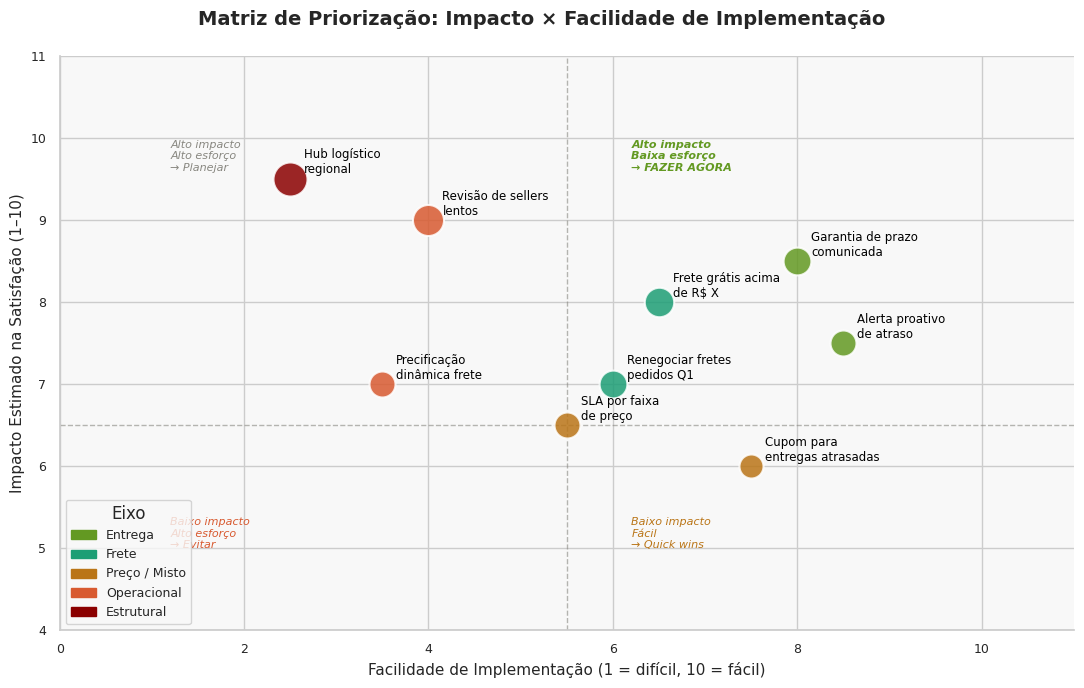

In [530]:
fig4, ax = plt.subplots(figsize=(11, 7))
fig4.suptitle("Matriz de Priorização: Impacto × Facilidade de Implementação",
              fontsize=14, fontweight="bold")
 
iniciativas = [
    # (label,                         impacto, facilidade, tamanho, cor)
    ("Garantia de prazo\ncomunicada",   8.5, 8.0, 400, CORES["positivo"]),
    ("Alerta proativo\nde atraso",      7.5, 8.5, 350, CORES["positivo"]),
    ("Frete grátis acima\nde R$ X",     8.0, 6.5, 450, CORES["secundaria"]),
    ("Renegociar fretes\npedidos Q1",   7.0, 6.0, 400, CORES["secundaria"]),
    ("SLA por faixa\nde preço",         6.5, 5.5, 350, CORES["amarelo"]),
    ("Cupom para\nentregas atrasadas",  6.0, 7.5, 300, CORES["amarelo"]),
    ("Revisão de sellers\nlentos",      9.0, 4.0, 500, CORES["alerta"]),
    ("Hub logístico\nregional",         9.5, 2.5, 600, CORES["critico"]),
    ("Precificação\ndinâmica frete",    7.0, 3.5, 350, CORES["alerta"]),
]
 
for label, imp, fac, tam, cor in iniciativas:
    ax.scatter(fac, imp, s=tam, color=cor, alpha=0.85,
               edgecolors="white", linewidth=1.5, zorder=3)
    ax.annotate(label, (fac, imp),
                textcoords="offset points", xytext=(10, 4),
                fontsize=8.5, color="black")
 
# Quadrantes
ax.axvline(5.5, color=CORES["neutro"], linestyle="--", linewidth=1, alpha=0.6)
ax.axhline(6.5, color=CORES["neutro"], linestyle="--", linewidth=1, alpha=0.6)
ax.text(1.2, 9.6, "Alto impacto\nAlto esforço\n→ Planejar", fontsize=8,
        color=CORES["neutro"], style="italic")
ax.text(6.2, 9.6, "Alto impacto\nBaixa esforço\n→ FAZER AGORA", fontsize=8,
        color=CORES["positivo"], fontweight="bold", style="italic")
ax.text(1.2, 5.0, "Baixo impacto\nAlto esforço\n→ Evitar", fontsize=8,
        color=CORES["alerta"], style="italic")
ax.text(6.2, 5.0, "Baixo impacto\nFácil\n→ Quick wins", fontsize=8,
        color=CORES["amarelo"], style="italic")
 
# Legenda de cores
patches = [
    mpatches.Patch(color=CORES["positivo"],  label="Entrega"),
    mpatches.Patch(color=CORES["secundaria"],label="Frete"),
    mpatches.Patch(color=CORES["amarelo"],   label="Preço / Misto"),
    mpatches.Patch(color=CORES["alerta"],    label="Operacional"),
    mpatches.Patch(color=CORES["critico"],   label="Estrutural"),
]
ax.legend(handles=patches, title="Eixo", loc="lower left", fontsize=9)
ax.set_xlim(0, 11)
ax.set_ylim(4, 11)
ax.set_xlabel("Facilidade de Implementação (1 = difícil, 10 = fácil)")
ax.set_ylabel("Impacto Estimado na Satisfação (1–10)")
ax.set_facecolor("#F8F8F8")
 
plt.tight_layout()
fig4.savefig("melhoria_fig4_priorizacao.png", dpi=150, bbox_inches="tight")
print("✓ melhoria_fig4_priorizacao.png")

# Remover grid de todos os eixos principais
for ax in axes:
    ax.grid(False)

# Remover grid do eixo secundário
ax2r.grid(False)

In [531]:
print("RFM colunas:")
print(rfm.columns)

print("\nReview cliente colunas:")
print(review_cliente.columns)

RFM colunas:
Index(['customer_id', 'ultima_compra', 'frequencia', 'primeiro_pedido',
       'recencia_dias', 'valor_total', 'ticket_medio', 'lifetime_dias',
       'r_score', 'f_score', 'm_score', 'rfm_score', 'risco_recencia',
       'risco_frequencia', 'risco_valor', 'review_medio', 'risco_review',
       'churn_score', 'segmento', 'nivel_risco'],
      dtype='str')

Review cliente colunas:
Index(['customer_id', 'review_medio'], dtype='str')


In [532]:
sep = "=" * 65
 
print(f"\n{sep}")
print("  RELATÓRIO DE OPORTUNIDADES DE MELHORIA")
print(sep)
 
print(f"""
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 EIXO 1 — TEMPO DE ENTREGA
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Diagnóstico:
   • Tempo médio de entrega:  {media_entrega:.1f} dias (mediana: {mediana_entrega:.0f} dias)
   • {pct_acima_21:.1f}% dos pedidos demoram mais de 21 dias
   • {pct_atrasado:.1f}% chegam após a data estimada
   • Atraso reduz o review em {queda_review_atraso:.2f} pontos (de {review_pontual:.2f} → {review_atrasado:.2f})
 
 Recomendações:
   ✅ [FAZER AGORA] Comunicação proativa: notificar o cliente
      por e-mail/push quando o pedido estiver prestes a atrasar.
      Custo baixo, alto impacto na percepção.
 
   ✅ [FAZER AGORA] Revisar a estimativa de prazo exibida na
      compra — prometer prazo mais conservador reduz a sensação
      de atraso mesmo sem mudar a logística.
 
   ⚠️  [PLANEJAR] Mapear os sellers com maior índice de atraso
      e negociar SLAs ou substituí-los. É o maior alavanca,
      mas requer negociação operacional.
 
   ⚠️  [PLANEJAR] Avaliar hub logístico regional para pedidos
      de regiões com tempo médio > 21 dias.
""")


  RELATÓRIO DE OPORTUNIDADES DE MELHORIA

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 EIXO 1 — TEMPO DE ENTREGA
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Diagnóstico:
   • Tempo médio de entrega:  12.1 dias (mediana: 10 dias)
   • 11.4% dos pedidos demoram mais de 21 dias
   • 6.8% chegam após a data estimada
   • Atraso reduz o review em 2.02 pontos (de 4.29 → 2.27)

 Recomendações:
   ✅ [FAZER AGORA] Comunicação proativa: notificar o cliente
      por e-mail/push quando o pedido estiver prestes a atrasar.
      Custo baixo, alto impacto na percepção.

   ✅ [FAZER AGORA] Revisar a estimativa de prazo exibida na
      compra — prometer prazo mais conservador reduz a sensação
      de atraso mesmo sem mudar a logística.

   ⚠️  [PLANEJAR] Mapear os sellers com maior índice de atraso
      e negociar SLAs ou substituí-los. É o maior alavanca,
      mas requer negociação operacional.

   ⚠️  [PLANEJAR] Avaliar hub logístico regional para pedidos
  

In [533]:
print(f"""━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 EIXO 2 — FRETE
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Diagnóstico:
   • Frete representa em média {media_frete_pct:.1f}% do valor do pedido
   • {pct_frete_alto:.1f}% dos pedidos têm frete > 35% do total
   • Review com frete ≤ 10%:  {review_frete_baixo:.2f}
   • Review com frete > 35%:  {review_frete_alto:.2f}
     → Diferença de {review_frete_baixo - review_frete_alto:.2f} pontos
 
 Recomendações:
   ✅ [FAZER AGORA] Criar frete grátis a partir de um valor
      mínimo de pedido (ex: R$ {ticket_mediano * 1.3:.0f}). Aumenta ticket médio
      e melhora a satisfação simultaneamente.
 
   ✅ [FAZER AGORA] Para pedidos Q1 (mais baratos), o frete
      representa proporção maior — oferecer opção de frete
      econômico com prazo maior, mas custo menor.
 
   ⚠️  [PLANEJAR] Renegociar tabela de frete com transportadoras
      para pedidos de baixo valor — atualmente o frete canibaliza
      a percepção de preço justo.
""")
 

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 EIXO 2 — FRETE
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Diagnóstico:
   • Frete representa em média 20.9% do valor do pedido
   • 13.7% dos pedidos têm frete > 35% do total
   • Review com frete ≤ 10%:  4.21
   • Review com frete > 35%:  4.11
     → Diferença de 0.10 pontos

 Recomendações:
   ✅ [FAZER AGORA] Criar frete grátis a partir de um valor
      mínimo de pedido (ex: R$ 137). Aumenta ticket médio
      e melhora a satisfação simultaneamente.

   ✅ [FAZER AGORA] Para pedidos Q1 (mais baratos), o frete
      representa proporção maior — oferecer opção de frete
      econômico com prazo maior, mas custo menor.

   ⚠️  [PLANEJAR] Renegociar tabela de frete com transportadoras
      para pedidos de baixo valor — atualmente o frete canibaliza
      a percepção de preço justo.



In [534]:
print(f"""━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 EIXO 3 — FAIXA DE PREÇO
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Diagnóstico:
   • Ticket médio geral:   R${ticket_medio_geral:,.2f}
   • Ticket mediano:       R${ticket_mediano:,.2f}
   • Review Q1 (barato):  {review_q1:.2f}
   • Review Q5 (caro):    {review_q5:.2f}
     → Clientes de alto valor têm {"melhor" if review_q5 > review_q1 else "pior"} experiência
 
 Recomendações:
   ✅ [FAZER AGORA] Priorizar SLA de entrega para pedidos de
      alto valor (Q4/Q5) — são os clientes com maior LTV e
      maior potencial de recompra.
 
   ✅ [FAZER AGORA] Para pedidos Q1, comunicar claramente o
      prazo mais longo para evitar frustração — expectativa
      gerenciada reduz reviews negativos.
 
   ⚠️  [PLANEJAR] Criar faixas de serviço diferenciadas por
      valor de pedido: frete expresso gratuito para Q5,
      frete subsidiado para Q3/Q4.
""")

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 EIXO 3 — FAIXA DE PREÇO
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Diagnóstico:
   • Ticket médio geral:   R$159.83
   • Ticket mediano:       R$105.28
   • Review Q1 (barato):  4.24
   • Review Q5 (caro):    4.04
     → Clientes de alto valor têm pior experiência

 Recomendações:
   ✅ [FAZER AGORA] Priorizar SLA de entrega para pedidos de
      alto valor (Q4/Q5) — são os clientes com maior LTV e
      maior potencial de recompra.

   ✅ [FAZER AGORA] Para pedidos Q1, comunicar claramente o
      prazo mais longo para evitar frustração — expectativa
      gerenciada reduz reviews negativos.

   ⚠️  [PLANEJAR] Criar faixas de serviço diferenciadas por
      valor de pedido: frete expresso gratuito para Q5,
      frete subsidiado para Q3/Q4.



In [535]:
print(f"""━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 RESUMO DE PRIORIDADES
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 🟢 FAZER AGORA (alto impacto, baixo esforço):
    1. Notificação proativa de atraso
    2. Revisão do prazo estimado exibido ao cliente
    3. Frete grátis acima de R${ticket_mediano * 1.3:.0f}
    4. Cupom de desconto para entregas atrasadas
 
 🟡 PLANEJAR (alto impacto, médio/alto esforço):
    5. SLA diferenciado por faixa de preço (Q4/Q5 prioritários)
    6. Auditoria e troca de sellers com alto índice de atraso
    7. Renegociação de frete para pedidos de baixo valor
 
 🔴 ESTRUTURAL (transformacional, longo prazo):
    8. Hub logístico regional para regiões críticas
    9. Precificação dinâmica de frete por distância e valor
{sep}
""")

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 RESUMO DE PRIORIDADES
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 🟢 FAZER AGORA (alto impacto, baixo esforço):
    1. Notificação proativa de atraso
    2. Revisão do prazo estimado exibido ao cliente
    3. Frete grátis acima de R$137
    4. Cupom de desconto para entregas atrasadas

 🟡 PLANEJAR (alto impacto, médio/alto esforço):
    5. SLA diferenciado por faixa de preço (Q4/Q5 prioritários)
    6. Auditoria e troca de sellers com alto índice de atraso
    7. Renegociação de frete para pedidos de baixo valor

 🔴 ESTRUTURAL (transformacional, longo prazo):
    8. Hub logístico regional para regiões críticas
    9. Precificação dinâmica de frete por distância e valor

